# Initialization

In [5]:
import xarray as xr
# import matplotlib as plt
from matplotlib import pyplot as plt
import pandas as pd
import geopandas as gpd
from math import sqrt
import seaborn as sns
import numpy as np
import cartopy


from sklearn import linear_model
from sklearn.model_selection import train_test_split
from sklearn.linear_model import BayesianRidge
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error 
from sklearn.preprocessing import StandardScaler

import warnings
warnings.filterwarnings('ignore')


#Choose whether to save plots
save_plots = False

# Change the matplotlib dpi to increase or decrease output size in vscode
plt.rcParams['figure.dpi'] = 150 

# Change some of the default xarray settings
xr.set_options(keep_attrs=True, display_expand_data=False)

def rmse(x,y):
    out = sqrt(mean_squared_error(x,y))
    return out




# Data Load-In

In [6]:

season_map = {

    12: 'Winter',
    1: 'Winter',
    2: 'Winter',
    3: 'Spring',
    4: 'Spring',
    5: 'Spring',
    6: 'Summer',
    7: 'Summer',
    8: 'Summer',
    9: 'Fall',
    10: 'Fall',
    11: 'Fall',
}

weekday_map = {
    0: 'Monday',
    1: 'Tuesday',
    2: 'Wednesday',
    3: 'Thursday',
    4: 'Friday',
    5: 'Saturday',
    6: 'Sunday'
}

datapath = "/home/nlring/Documents/01_Research/larc-chicago-haq/datasets/"

fulldat = pd.read_csv(datapath+"fulldat-unaggregated-pixelmask.csv")
fulldat['datetime'] = pd.to_datetime(fulldat['datetime'], errors='coerce')
fulldat['hour'] = fulldat['datetime'].dt.hour
fulldat['weekday'] = fulldat['datetime'].dt.weekday
fulldat['season'] = fulldat['month'].map(season_map)

hourly = pd.read_csv(datapath+"fulldat-hourly-timeseries.csv")
hourly['datetime'] = pd.to_datetime(hourly['datetime'], errors='coerce')
hourly['month'] = hourly['datetime'].dt.month
hourly['hour'] = hourly['datetime'].dt.hour
hourly['weekday'] = hourly['datetime'].dt.weekday
hourly['season'] = hourly['month'].map(season_map)

# diurnal = pd.read_csv(datapath+"fulldat-diurnal-aggregation.csv")
# weekly = pd.read_csv(datapath+"fulldat-weekly-aggregation.csv")
# monthly_diurnal = pd.read_csv(datapath+"fulldat-monthly-diurnal-aggregation.csv")
# seasonal_diurnal = pd.read_csv(datapath+"fulldat-seasonal-diurnal-aggregation.csv")
# monthly = pd.read_csv(datapath+"fulldat-monthly-aggregation.csv")



In [7]:
hourly

,Unnamed: 0,datetime,latitude,longitude,col_no2_mean,col_no2_median,col_no2_var,col_no2_sd,sfc_no2_mean,sfc_no2_median,...,v2m_mean,v2m_median,u10m_mean,u10m_median,v10m_mean,v10m_median,month,hour,weekday,season
0,0,2025-09-01,41.65,-87.61,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,9,0,0,Fall
1,1,2025-09-01,41.65,-87.57,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,9,0,0,Fall
2,2,2025-09-01,41.65,-87.55,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,9,0,0,Fall
3,3,2025-09-01,41.65,-87.53,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,9,0,0,Fall
4,4,2025-09-01,41.67,-87.67,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,9,0,0,Fall
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9926100,9926100,2026-06-15,42.01,-87.81,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6,0,0,Summer
9926101,9926101,2026-06-15,42.01,-87.79,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6,0,0,Summer
9926102,9926102,2026-06-15,42.01,-87.77,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6,0,0,Summer
9926103,9926103,2026-06-15,42.01,-87.71,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,6,0,0,Summer


# MLR Over Hourly Timeseries Data 


In [32]:
var_select = ['sfc_no2_mean','col_no2_mean','pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean', 'u10m_mean', 'v10m_mean']
target_col = 'sfc_no2_mean'
feature_cols = ['col_no2_mean', 'pbl_mean', 'solar_zenith_mean', 'u2m_mean', 'v2m_mean', 'u10m_mean', 'v10m_mean']

model_frame = hourly[var_select].dropna().copy()

train_df, test_df = train_test_split(model_frame, test_size=0.2, random_state=1219)

scaler_x = StandardScaler().fit(train_df[feature_cols])
scaler_y = StandardScaler().fit(train_df[[target_col]])

x_train = pd.DataFrame(scaler_x.transform(train_df[feature_cols]), columns=feature_cols, index=train_df.index)
x_test = pd.DataFrame(scaler_x.transform(test_df[feature_cols]), columns=feature_cols, index=test_df.index)

y_train = pd.Series(scaler_y.transform(train_df[[target_col]]).ravel(), name=target_col, index=train_df.index)
y_test = pd.Series(scaler_y.transform(test_df[[target_col]]).ravel(), name=target_col, index=test_df.index)


print(f"Train rows: {len(train_df)}, Test rows: {len(test_df)}")

model = linear_model.LinearRegression().fit(X=x_train, y=y_train)

train_score = r2_score(y_train, model.predict(x_train))
test_score = r2_score(y_test, model.predict(x_test))

print(f"\nTrain R2: {train_score:.3f}")
print(f"Test R2: {test_score:.3f}")

coef = np.ravel(model.coef_)
intercept = float(model.intercept_)

print("Coef: ", coef)
print("Intercept: ", intercept)


def estimate_no2(col_no2, pbl, sza, u2m, v2m, u10m, v10m):
    return (intercept + coef[0] * col_no2 + coef[1] * pbl + coef[2] * sza 
            + coef[3] * u2m + coef[4] * v2m + coef[5]*u10m + coef[6]*v10m)

x_train_est = x_train.copy()
x_train_est['no2_estimate'] = x_train_est.apply(
    lambda row: estimate_no2(
        row.col_no2_mean,
        row.pbl_mean,
        row.solar_zenith_mean,
        row.u2m_mean,
        row.v2m_mean,
        row.u10m_mean,
        row.v10m_mean,
    ),
    axis=1,
)

# Convert the scaled prediction back to the original NO2 units.
x_train_est['no2_estimate_unscaled'] = scaler_y.inverse_transform(x_train_est[['no2_estimate']]).ravel()


x_test_est = x_test.copy()
x_test_est['no2_estimate'] = x_test_est.apply(
    lambda row: estimate_no2(
        row.col_no2_mean,
        row.pbl_mean,
        row.solar_zenith_mean,
        row.u2m_mean,
        row.v2m_mean,
        row.u10m_mean,
        row.v10m_mean,
    ),
    axis=1,
)

# Convert the scaled prediction back to the original NO2 units.
x_test_est['no2_estimate_unscaled'] = scaler_y.inverse_transform(x_test_est[['no2_estimate']]).ravel()



Train rows: 114431, Test rows: 28608

Train R2: 0.273
Test R2: 0.278
Coef:  [ 0.21785162 -0.33082037  0.18053823 -0.62393478 -0.57727737  0.71326464
  0.74950476]
Intercept:  1.1334640032066413e-17


## Plots

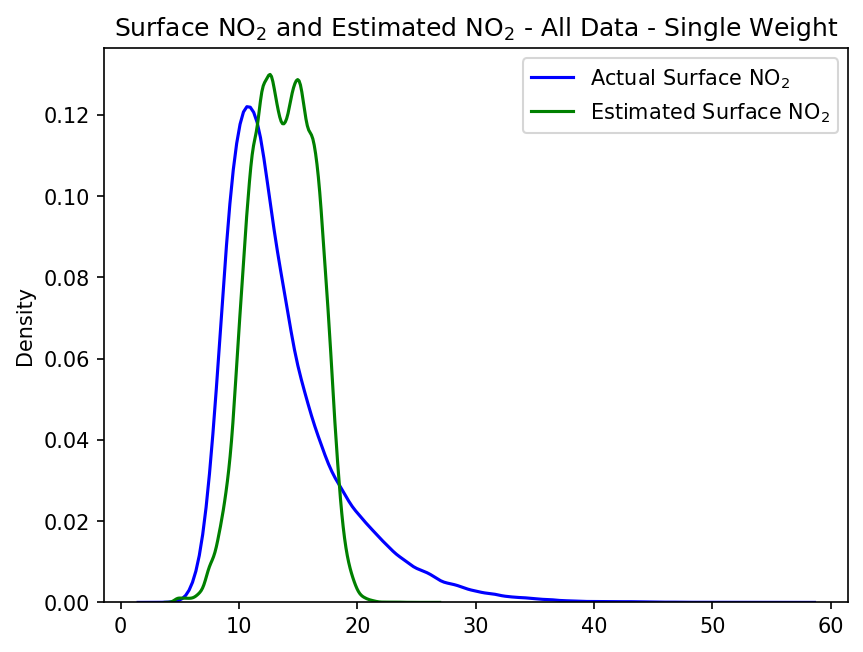

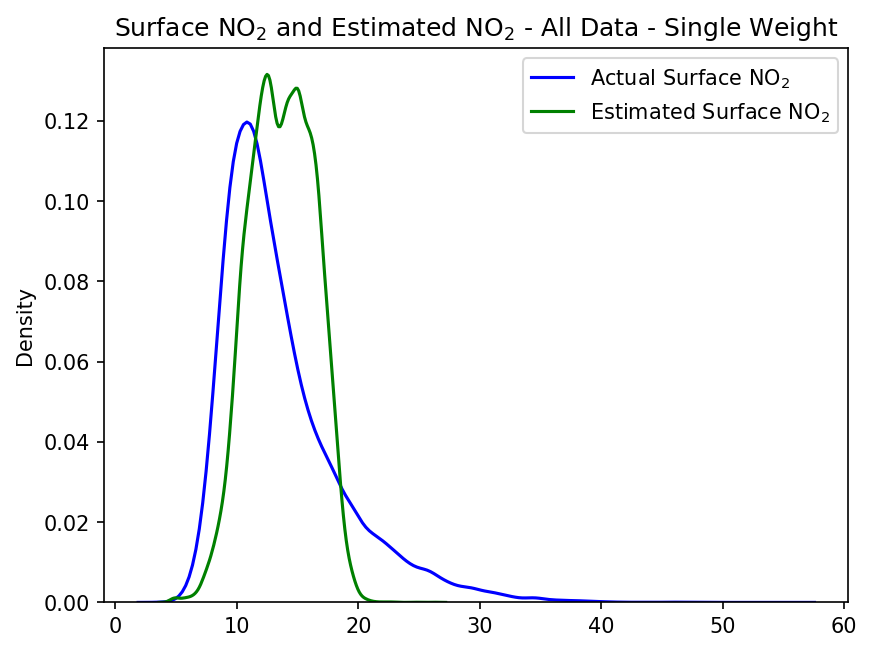

In [33]:
actual_surface = train_df['sfc_no2_mean'].to_numpy()
estimated_surface = x_train_est['no2_estimate_unscaled'].to_numpy()
actual_surface_test = test_df['sfc_no2_mean'].to_numpy()
estimated_surface_test = x_test_est['no2_estimate_unscaled'].to_numpy()


sns.kdeplot(actual_surface, color='blue', label='Actual Surface NO$_2$')
sns.kdeplot(estimated_surface, color='green', label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - All Data - Single Weight")
plt.legend()
# savefig("kde-actual-and-estimated-single-weight.png")
plt.show()

sns.kdeplot(actual_surface_test, color='blue', label='Actual Surface NO$_2$')
sns.kdeplot(estimated_surface_test, color='green', label='Estimated Surface NO$_2$')
plt.title("Surface NO$_2$ and Estimated NO$_2$ - All Data - Single Weight")
plt.legend()
# savefig("kde-actual-and-estimated-single-weight.png")
plt.show()

# eqn_text = f"y = 

# Monthly Regressions

In [48]:
var_select = ['sfc_no2_mean','col_no2_mean','pbl_mean', 'solar_zenith_mean', 'u10m_mean','v10m_mean']
target_col = 'sfc_no2_mean'
feature_cols = ['col_no2_mean', 'pbl_mean', 'solar_zenith_mean','u10m_mean','v10m_mean']
meta_cols = ['datetime', 'latitude', 'longitude']

def estimate_no2_from_model(x):
    return (
        intercept
        + coef[0] * x['col_no2_mean']
        + coef[1] * x['pbl_mean']
        + coef[2] * x['solar_zenith_mean']
        + coef[3] * x['u10m_mean']
        + coef[4] * x['v10m_mean']
    )

month_results = []
monthly_estimates = []

for month in sorted(hourly['datetime'].dt.month.dropna().unique()):
    month_frame = hourly.loc[
        hourly['datetime'].dt.month == month,
        meta_cols + var_select
    ].dropna().copy()
    if len(month_frame) < 10:
        continue

    train_df, test_df = train_test_split(month_frame, test_size=0.2, random_state=20)

    scaler_x = StandardScaler().fit(train_df[feature_cols])
    scaler_y = StandardScaler().fit(train_df[[target_col]])

    x_train = pd.DataFrame(scaler_x.transform(train_df[feature_cols]), columns=feature_cols, index=train_df.index)
    x_test = pd.DataFrame(scaler_x.transform(test_df[feature_cols]), columns=feature_cols, index=test_df.index)

    y_train = pd.Series(scaler_y.transform(train_df[[target_col]]).ravel(), name=target_col, index=train_df.index)
    y_test = pd.Series(scaler_y.transform(test_df[[target_col]]).ravel(), name=target_col, index=test_df.index)

    model = linear_model.LinearRegression().fit(X=x_train, y=y_train)

    intercept = float(model.intercept_)
    coef = np.ravel(model.coef_)

    train_est_scaled = x_train.apply(estimate_no2_from_model, axis=1)
    test_est_scaled = x_test.apply(estimate_no2_from_model, axis=1)

    train_estimates = scaler_y.inverse_transform(pd.DataFrame(train_est_scaled, columns=['no2_estimate'])).ravel()
    test_estimates = scaler_y.inverse_transform(pd.DataFrame(test_est_scaled, columns=['no2_estimate'])).ravel()

    train_estimates_2 = scaler_y

    train_est = train_df[meta_cols + ['sfc_no2_mean']].copy()
    train_est['no2_estimate'] = train_estimates
    train_est['month'] = month
    train_est['split'] = 'train'
    train_est['residual'] = train_est['sfc_no2_mean'] - train_est['no2_estimate']

    test_est = test_df[meta_cols + ['sfc_no2_mean']].copy()
    test_est['no2_estimate'] = test_estimates
    test_est['month'] = month
    test_est['split'] = 'test'
    test_est['residual'] = test_est['sfc_no2_mean'] - test_est['no2_estimate']

    monthly_estimates.append(pd.concat([train_est, test_est], axis=0))

    month_results.append({
        'month': month,
        'train_rows': len(train_df),
        'test_rows': len(test_df),
        'train_r2': r2_score(y_train, model.predict(x_train)),
        'test_r2': r2_score(y_test, model.predict(x_test)),
        'intercept': intercept,
        'coef_col_no2': float(coef[0]),
        'coef_pbl': float(coef[1]),
        'coef_sza': float(coef[2]),
        'coef_u10m': float(coef[3]),
        'coef_v10m': float(coef[4]),
    })

model_vals = pd.DataFrame(month_results)
print(model_vals)

monthly_estimates_df = pd.concat(monthly_estimates, axis=0, ignore_index=True)
print(monthly_estimates_df.head())

monthly_estimates_df = monthly_estimates_df.sort_values(by='datetime')


monthly_estimates_df.to_csv(datapath + "monthly-no2-estimates.csv")

monthly_estimates_df

   month  train_rows  test_rows  train_r2   test_r2     intercept  \
0    1.0        3564        891  0.175793  0.164552  9.996639e-16   
1    2.0        8840       2211  0.375922  0.378647 -2.556664e-16   
2    3.0       13362       3341  0.227099  0.234034 -2.927923e-16   
3    4.0       11961       2991  0.355772  0.366614 -5.855327e-16   
4    5.0       19880       4971  0.305273  0.298723  1.271728e-16   
5    9.0       24684       6171  0.310471  0.305738  3.160885e-16   
6   10.0       18185       4547  0.279173  0.280203  2.803575e-16   
7   11.0       10958       2740  0.431622  0.416704  2.543452e-18   
8   12.0        2993        749  0.178633  0.179139  3.630072e-17   

   coef_col_no2  coef_pbl  coef_sza  coef_u10m  coef_v10m  
0      0.026229 -0.409907  0.229320   0.012279  -0.247258  
1      0.194879 -0.451956  0.139400  -0.096200   0.148230  
2      0.199142 -0.381702  0.093145   0.065406   0.196232  
3      0.218208 -0.218567  0.226027   0.169613   0.377502  
4      0.

,datetime,latitude,longitude,sfc_no2_mean,no2_estimate,month,split,residual
76229,2025-09-04 12:00:00,41.75,-87.69,9.530000,13.113825,9.0,train,-3.583825
102711,2025-09-04 12:00:00,41.67,-87.63,12.774000,13.152236,9.0,test,-0.378236
90872,2025-09-04 12:00:00,41.67,-87.65,12.463333,13.177814,9.0,train,-0.714481
73105,2025-09-04 12:00:00,41.93,-87.79,9.253636,12.767482,9.0,train,-3.513846
102595,2025-09-04 12:00:00,41.89,-87.73,13.296667,12.641764,9.0,test,0.654903
...,...,...,...,...,...,...,...,...
58442,2026-05-31 23:00:00,42.01,-87.81,10.088182,15.381555,5.0,train,-5.293373
62231,2026-05-31 23:00:00,42.01,-87.79,10.232727,16.238484,5.0,train,-6.005756
67004,2026-05-31 23:00:00,41.97,-87.87,14.002581,15.333406,5.0,train,-1.330825
63897,2026-05-31 23:00:00,42.01,-87.77,10.641000,16.243106,5.0,train,-5.602106


## Plots

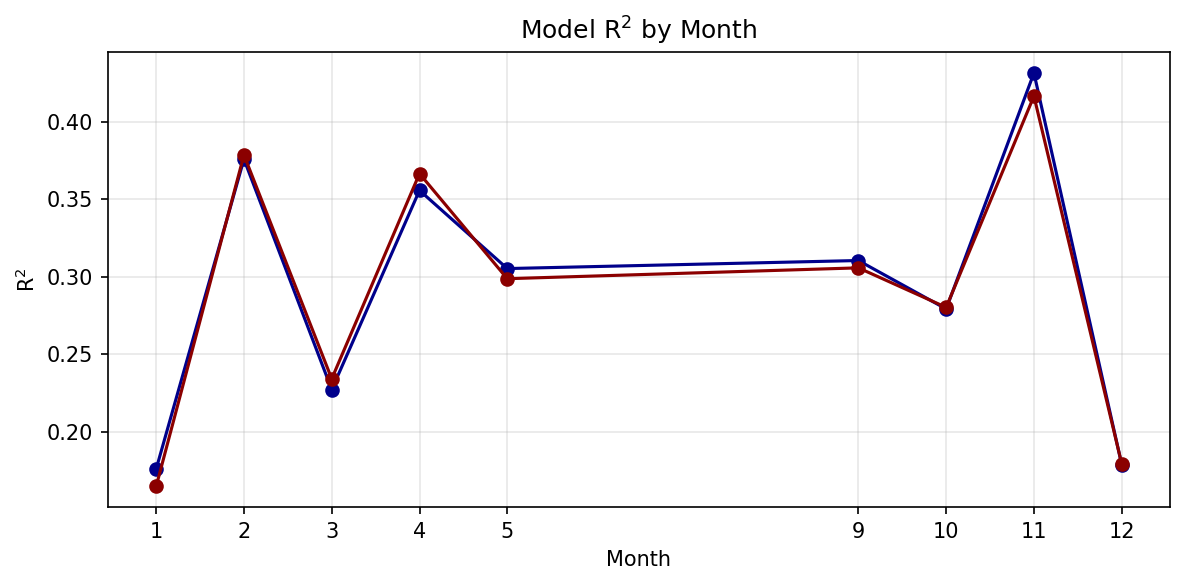

In [49]:
plt.figure(figsize=(8, 4))
plt.plot(model_vals['month'], model_vals['train_r2'], marker='o', color='darkblue')
plt.plot(model_vals['month'], model_vals['test_r2'], marker='o', color='darkred')
plt.xticks(model_vals['month'])
plt.xlabel('Month')
plt.ylabel('R$^2$')
plt.title('Model R$^2$ by Month')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("model-r2-monthly.png")
plt.show()


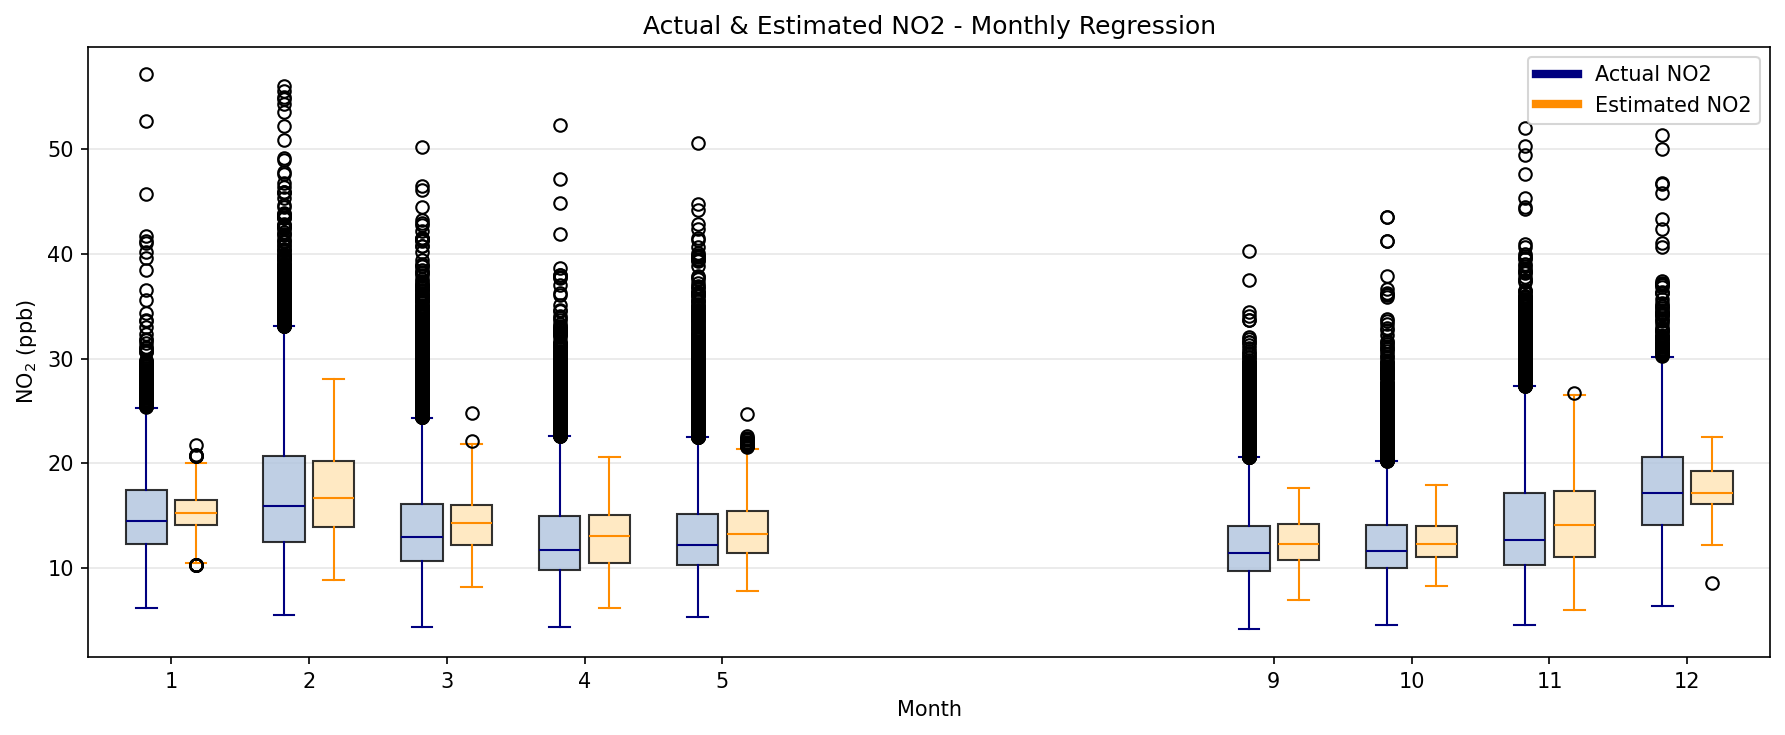

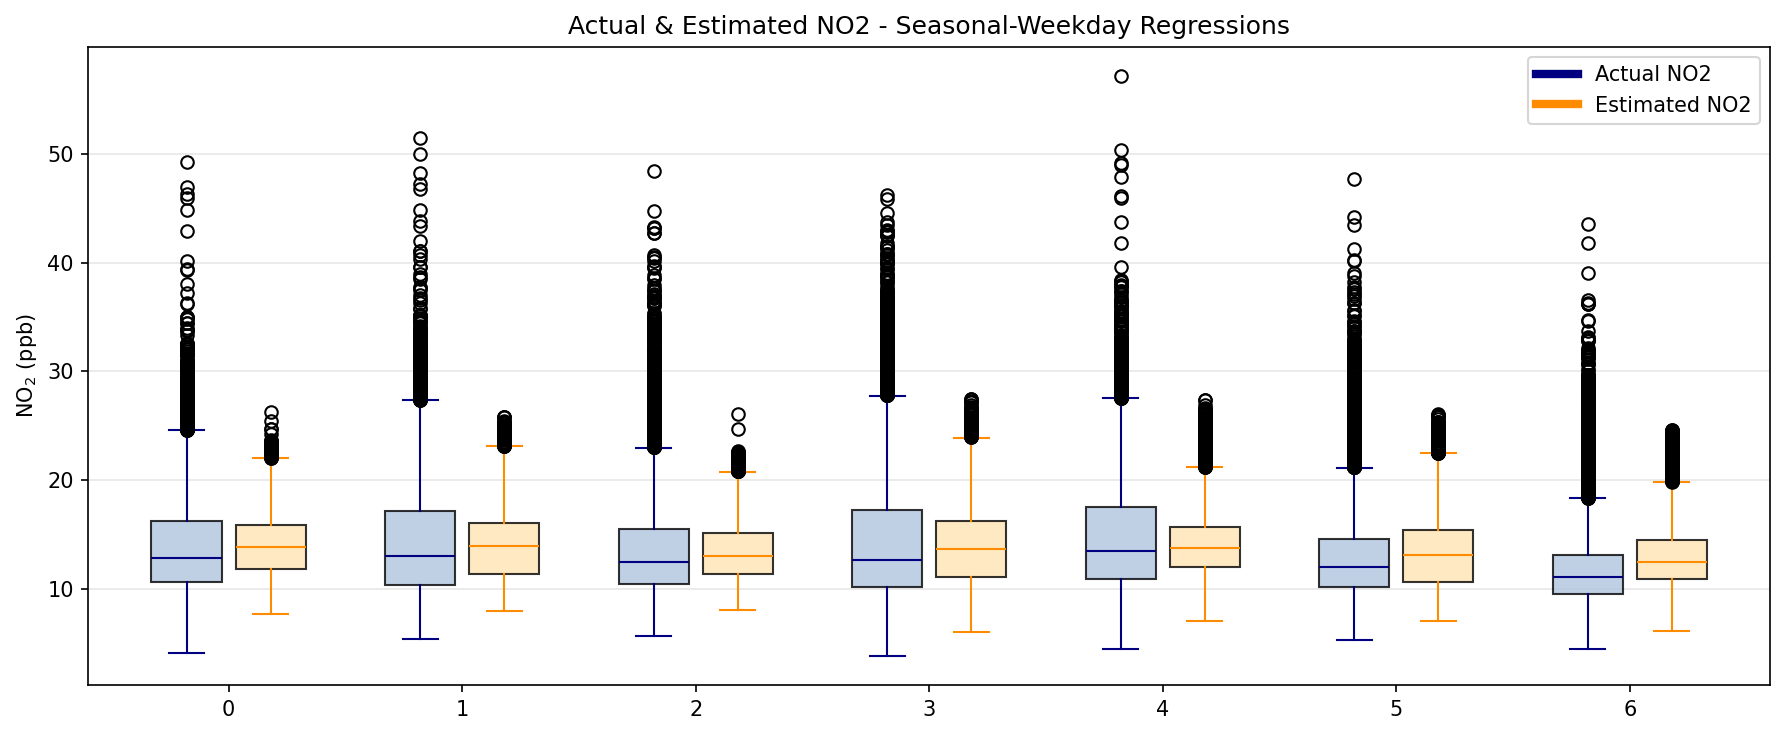

In [50]:
max_points_per_box = 10000

monthly_estimates_plot = (
    monthly_estimates_df[['datetime','month', 'sfc_no2_mean', 'no2_estimate']]
    .dropna(subset=['sfc_no2_mean', 'no2_estimate'])
    .copy()
)
monthly_estimates_plot['month'] = monthly_estimates_plot['month'].astype(int)
monthly_estimates_plot['weekday'] = monthly_estimates_plot['datetime'].dt.weekday

months = []
actual_by_hour = []
estimated_by_hour = []

rng = np.random.default_rng(41)

for month, group in monthly_estimates_plot.groupby('month', sort=True):
    months.append(int(month))

    actual_values = group['sfc_no2_mean'].to_numpy(dtype=float)
    estimated_values = group['no2_estimate'].to_numpy(dtype=float)

    if len(actual_values) > max_points_per_box:
        sample_idx = rng.choice(len(actual_values), size=max_points_per_box, replace=False)
        actual_values = actual_values[sample_idx]
        estimated_values = estimated_values[sample_idx]

    actual_by_hour.append(actual_values)
    estimated_by_hour.append(estimated_values)

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [month - 0.18 for month in months]
positions_estimated = [month + 0.18 for month in months]

ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_hour,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(months)
ax.set_xticklabels(months)
ax.set_xlim(min(months) - 0.6, max(months) + 0.6)
ax.set_xlabel('Month')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Actual & Estimated NO2 - Monthly Regression')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()
plt.savefig('month-boxplot-monthly-regressoin.png')
plt.show()

#---------------------------------------------------------------------------------------------------------------------#

weekday_labels = []
actual_by_weekday = []
estimated_by_weekday = []

for weekday, group in monthly_estimates_plot.groupby('weekday', sort=True):
    weekday_labels.append(int(weekday))

    actual_values = group['sfc_no2_mean'].to_numpy(dtype=float)
    estimated_values = group['no2_estimate'].to_numpy(dtype=float)

    if len(actual_values) > max_points_per_box:
        sample_idx = rng.choice(len(actual_values), size=max_points_per_box, replace=False)
        actual_values = actual_values[sample_idx]
        estimated_values = estimated_values[sample_idx]

    actual_by_weekday.append(actual_values)
    estimated_by_weekday.append(estimated_values)

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [weekday - 0.18 for weekday in weekday_labels]
positions_estimated = [weekday + 0.18 for weekday in weekday_labels]

ax.boxplot(
    actual_by_weekday,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_weekday,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(weekday_labels)
ax.set_xticklabels(weekday_labels)
ax.set_xlim(min(weekday_labels) - 0.6, max(weekday_labels) + 0.6)
ax.set_xlabel('')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Actual & Estimated NO2 - Seasonal-Weekday Regressions')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()
plt.savefig('weekday-boxplot-monthly-regression.png')
plt.show()

# Seasonal Day of Week Regressions

In [ ]:

var_select = ['sfc_no2_mean','col_no2_mean','pbl_mean', 'solar_zenith_mean', 'u10m_mean','v10m_mean']
target_col = 'sfc_no2_mean'
feature_cols = ['col_no2_mean', 'pbl_mean', 'solar_zenith_mean','u10m_mean','v10m_mean']
meta_cols = ['datetime', 'latitude', 'longitude']

def estimate_no2_from_model(x):
    return (
        intercept
        + coef[0] * x['col_no2_mean']
        + coef[1] * x['pbl_mean']
        + coef[2] * x['solar_zenith_mean']
        + coef[3] * x['u10m_mean']
        + coef[4] * x['v10m_mean']
    )

hourly = hourly.mask(hourly['season']=='Summer')

month_results = []
monthly_estimates = []
scale_factor_rows = []

for season in sorted(hourly['season'].dropna().unique()):
    for weekday in sorted(hourly['weekday'].dropna().unique()):
        month_frame = hourly.loc[
            ((hourly['weekday'] == weekday) & (hourly['season']==season)),
            meta_cols + var_select
        ].dropna().copy()
        if len(month_frame) < 10:
            continue

        train_df, test_df = train_test_split(month_frame, test_size=0.2, random_state=42)

        scaler_x = StandardScaler().fit(train_df[feature_cols])
        scaler_y = StandardScaler().fit(train_df[[target_col]])

        for feature_name, feature_mean, feature_scale in zip(feature_cols, scaler_x.mean_, scaler_x.scale_):
            scale_factor_rows.append({
                'season': season,
                'weekday': weekday,
                'scaler': 'x',
                'variable': feature_name,
                'mean': float(feature_mean),
                'scale_factor': float(feature_scale),
            })

        scale_factor_rows.append({
            'season': season,
            'weekday': weekday,
            'scaler': 'y',
            'variable': target_col,
            'mean': float(scaler_y.mean_[0]),
            'scale_factor': float(scaler_y.scale_[0]),
        })

        x_train = pd.DataFrame(scaler_x.transform(train_df[feature_cols]), columns=feature_cols, index=train_df.index)
        x_test = pd.DataFrame(scaler_x.transform(test_df[feature_cols]), columns=feature_cols, index=test_df.index)

        y_train = pd.Series(scaler_y.transform(train_df[[target_col]]).ravel(), name=target_col, index=train_df.index)
        y_test = pd.Series(scaler_y.transform(test_df[[target_col]]).ravel(), name=target_col, index=test_df.index)

        model = linear_model.LinearRegression().fit(X=x_train, y=y_train)

        intercept = float(model.intercept_)
        coef = np.ravel(model.coef_)

        train_est_scaled = x_train.apply(estimate_no2_from_model, axis=1)
        test_est_scaled = x_test.apply(estimate_no2_from_model, axis=1)

        train_estimates = scaler_y.inverse_transform(pd.DataFrame(train_est_scaled, columns=['no2_estimate'])).ravel()
        test_estimates = scaler_y.inverse_transform(pd.DataFrame(test_est_scaled, columns=['no2_estimate'])).ravel()

        train_estimates_2 = scaler_y

        train_est = train_df[meta_cols + ['sfc_no2_mean','col_no2_mean']].copy()
        train_est['no2_estimate'] = train_estimates
        train_est['weekday'] = weekday 
        train_est['season'] = season
        train_est['split'] = 'train'
        train_est['residual'] = train_est['no2_estimate'] - train_est['sfc_no2_mean']

        test_est = test_df[meta_cols + ['sfc_no2_mean','col_no2_mean']].copy()
        test_est['no2_estimate'] = test_estimates
        test_est['weekday'] = weekday 
        test_est['season'] = season
        test_est['split'] = 'test'
        test_est['residual'] = test_est['no2_estimate'] - test_est['sfc_no2_mean']


        monthly_estimates.append(pd.concat([train_est, test_est], axis=0))

        month_results.append({
            'weekday': weekday,
            'season': season,
            'train_rows': len(train_df),
            'test_rows': len(test_df),
            'train_r2': r2_score(y_train, model.predict(x_train)),
            'test_r2': r2_score(y_test, model.predict(x_test)),
            'train_rmse': root_mean_squared_error(y_train, model.predict(x_train)),
            'test_rmse': root_mean_squared_error(y_test, model.predict(x_test)),
            'intercept': intercept,
            'coef_col_no2': float(coef[0]),
            'coef_pbl': float(coef[1]),
            'coef_sza': float(coef[2]),
            'coef_u10m': float(coef[3]),
            'coef_v10m': float(coef[4]),
        })

model_vals = pd.DataFrame(month_results)
print(model_vals)
model_vals.to_csv(datapath+"seasonal-weekday-model-values.csv")

monthly_estimates_df = pd.concat(monthly_estimates, axis=0, ignore_index=True)
print(monthly_estimates_df.head())

monthly_estimates_df = monthly_estimates_df.sort_values(by='datetime')
monthly_estimates_df['month'] = monthly_estimates_df['datetime'].dt.month

monthly_estimates_df.to_csv(datapath + "seasonal-dayofweek-no2-estimates.csv")

scale_factors = pd.DataFrame(scale_factor_rows)
print(scale_factors.head())

scale_factor_means = scale_factors.pivot(index=['season', 'weekday'], columns='variable', values='mean').add_prefix('scale_mean_')
scale_factor_values = scale_factors.pivot(index=['season', 'weekday'], columns='variable', values='scale_factor').add_prefix('scale_fact_')
scale_factor_wide = pd.concat([scale_factor_means, scale_factor_values], axis=1).reset_index()
print(scale_factor_wide.head())

scale_factors.to_csv(datapath + 'seasonal-weekday-scale-factors.csv', index=False)
scale_factor_wide.to_csv(datapath + 'seasonal-weekday-scale-factors-wide.csv', index=False)

scale_factor_wide

    weekday  season  train_rows  test_rows  train_r2   test_r2  train_rmse  \
0       0.0    Fall        8688       2173  0.377389  0.352256    0.789057   
1       1.0    Fall        5088       1272  0.316791  0.345688    0.826564   
2       2.0    Fall        5770       1443  0.304179  0.318802    0.834159   
3       3.0    Fall       10675       2669  0.361789  0.348806    0.798881   
4       4.0    Fall        8752       2188  0.356930  0.351272    0.801917   
5       5.0    Fall        4727       1182  0.356726  0.311251    0.802043   
6       6.0    Fall       10126       2532  0.175875  0.125648    0.907813   
7       0.0  Spring        9864       2467  0.269512  0.255632    0.854686   
8       1.0  Spring        3448        863  0.435800  0.431513    0.751133   
9       2.0  Spring        5520       1380  0.374874  0.367106    0.790649   
10      3.0  Spring        8340       2085  0.418194  0.424572    0.762762   
11      4.0  Spring        4555       1139  0.271766  0.321268  

variable,season,weekday,scale_mean_col_no2_mean,scale_mean_pbl_mean,scale_mean_sfc_no2_mean,scale_mean_solar_zenith_mean,scale_mean_u10m_mean,scale_mean_v10m_mean,scale_fact_col_no2_mean,scale_fact_pbl_mean,scale_fact_sfc_no2_mean,scale_fact_solar_zenith_mean,scale_fact_u10m_mean,scale_fact_v10m_mean
0,Fall,0.0,7.452620e+15,829.472548,13.334098,59.331167,-0.461286,1.254289,3.826323e+15,450.368276,4.477724,11.647022,3.475234,3.153221
1,Fall,1.0,5.145091e+15,803.236046,12.669908,58.040652,-1.123723,0.929063,2.504017e+15,353.618624,4.248563,11.409974,3.356671,3.893406
2,Fall,2.0,5.984032e+15,848.308752,12.846086,59.590442,-0.555427,-1.875370,3.287919e+15,430.935686,4.197701,11.708130,4.865122,3.070540
3,Fall,3.0,8.209054e+15,835.735550,13.123478,59.203553,0.188282,-0.691975,4.180762e+15,487.558021,5.167281,11.391809,3.158153,3.061435
4,Fall,4.0,7.770791e+15,855.118373,14.044631,60.445796,2.492586,0.792337,2.974549e+15,559.662427,4.933326,10.181392,3.304813,2.589467
5,Fall,5.0,5.127250e+15,1035.962767,13.048968,59.994666,1.781097,1.532676,3.028622e+15,789.318159,3.848111,9.816727,3.167066,2.308806
6,Fall,6.0,4.528944e+15,930.606903,11.278692,59.975759,-0.185302,0.308520,2.084824e+15,500.607489,2.661740,11.074793,3.817828,3.811621
7,Spring,0.0,5.977899e+15,840.845752,13.535816,51.554458,0.543339,0.572686,3.380383e+15,506.333653,4.254449,15.170249,3.485149,4.868615
8,Spring,1.0,4.662089e+15,854.660238,12.814505,46.936570,0.802107,0.981160,2.293009e+15,270.016536,4.365950,14.032477,4.046834,4.372322
9,Spring,2.0,5.759178e+15,672.713406,14.146257,51.286853,0.300744,-1.911820,4.587272e+15,483.020358,5.575857,16.728964,2.108645,4.290406


## Plots

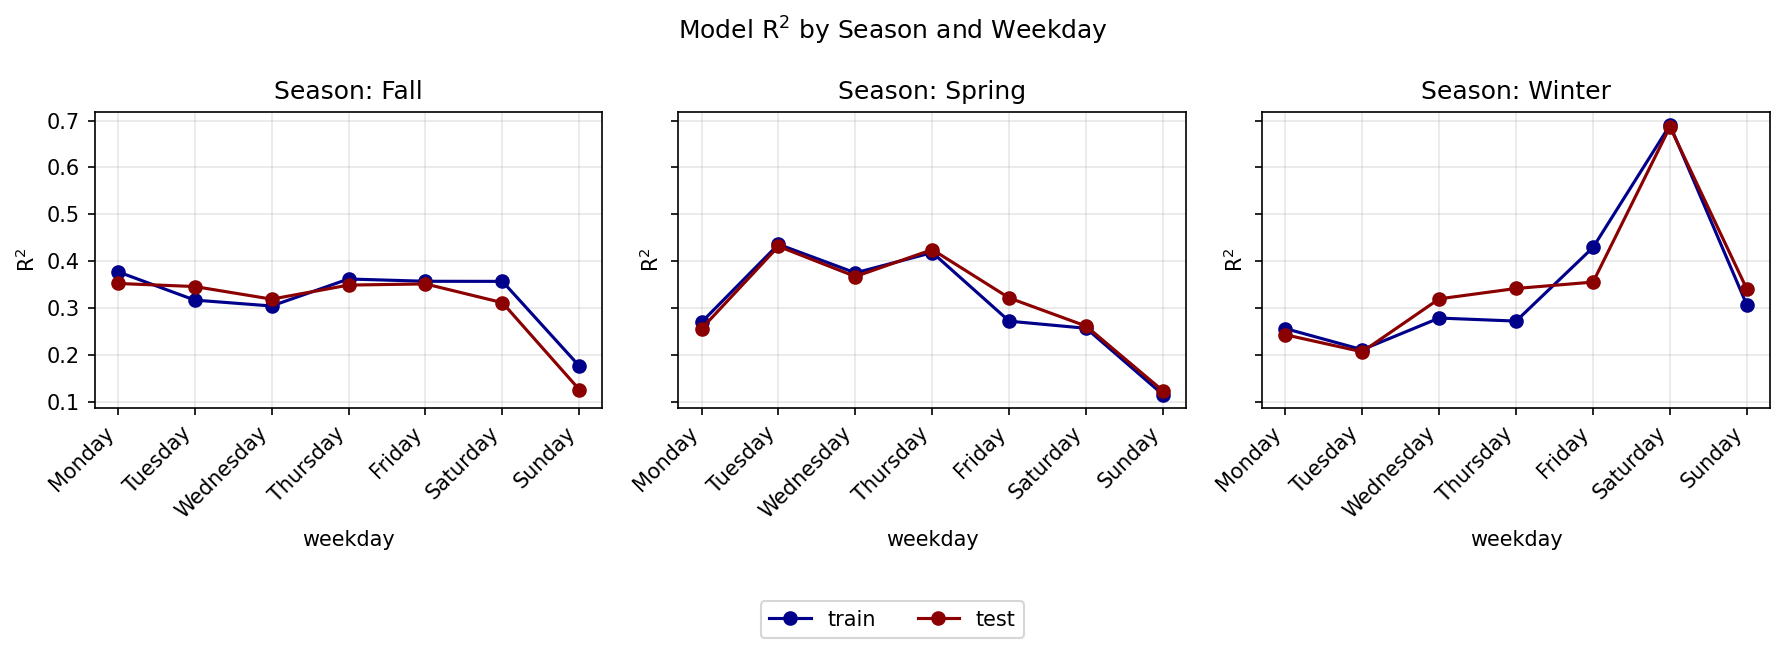

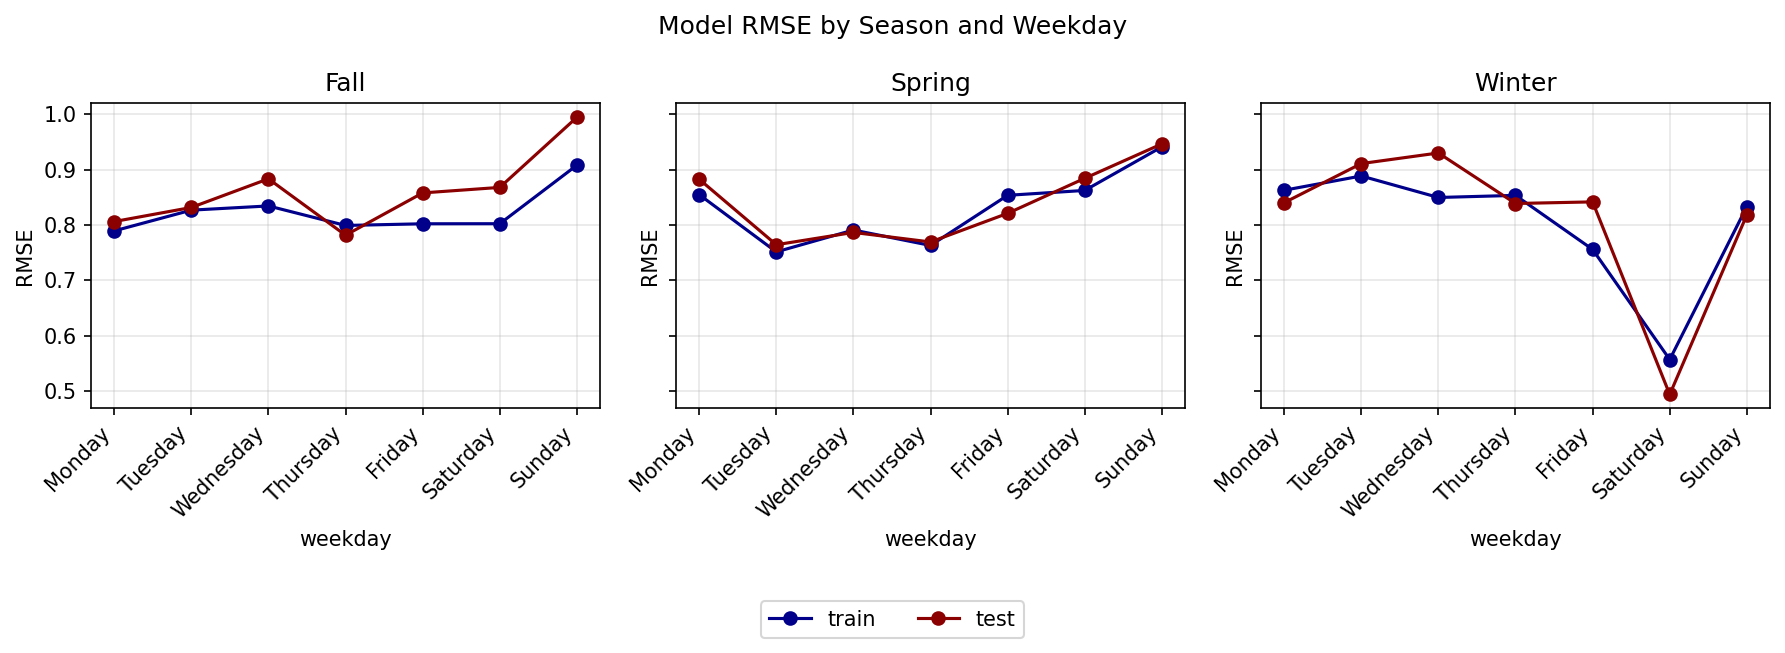

In [5]:
season_order = sorted(model_vals['season'].dropna().unique())

fig, axes = plt.subplots(
    nrows=1,
    ncols=len(season_order),
    figsize=(4 * len(season_order), 4),
    sharey=True,
)

if len(season_order) == 1:
    axes = [axes]

for ax, season_name in zip(axes, season_order):
    season_data = model_vals[model_vals['season'] == season_name]
    ax.plot(season_data['weekday'], season_data['train_r2'], marker='o', color='darkblue', label='train')
    ax.plot(season_data['weekday'], season_data['test_r2'], marker='o', color='darkred', label='test')
    ax.set_xticks(season_data['weekday'])
    ax.set_xticklabels(season_data['weekday'].map(weekday_map), rotation=45, ha='right')
    ax.set_xlabel('weekday')
    ax.set_ylabel('R$^2$')
    ax.set_title(f'Season: {season_name}')
    ax.grid(True, alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=2)
fig.suptitle('Model R$^2$ by Season and Weekday')
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig('r2-seasonal-weekday.png')
plt.show()


fig, axes = plt.subplots(
    nrows=1,
    ncols=len(season_order),
    figsize=(4 * len(season_order), 4),
    sharey=True,
)

if len(season_order) == 1:
    axes = [axes]

for ax, season_name in zip(axes, season_order):
    season_data = model_vals[model_vals['season'] == season_name]
    ax.plot(season_data['weekday'], season_data['train_rmse'], marker='o', color='darkblue', label='train')
    ax.plot(season_data['weekday'], season_data['test_rmse'], marker='o', color='darkred', label='test')
    ax.set_xticks(season_data['weekday'])
    ax.set_xticklabels(season_data['weekday'].map(weekday_map), rotation=45, ha='right')
    ax.set_xlabel('weekday')
    ax.set_ylabel('RMSE')
    ax.set_title(f'{season_name}')
    ax.grid(True, alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=2)
fig.suptitle('Model RMSE by Season and Weekday')
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig('rmse-seasonal-weekday.png')
plt.show()

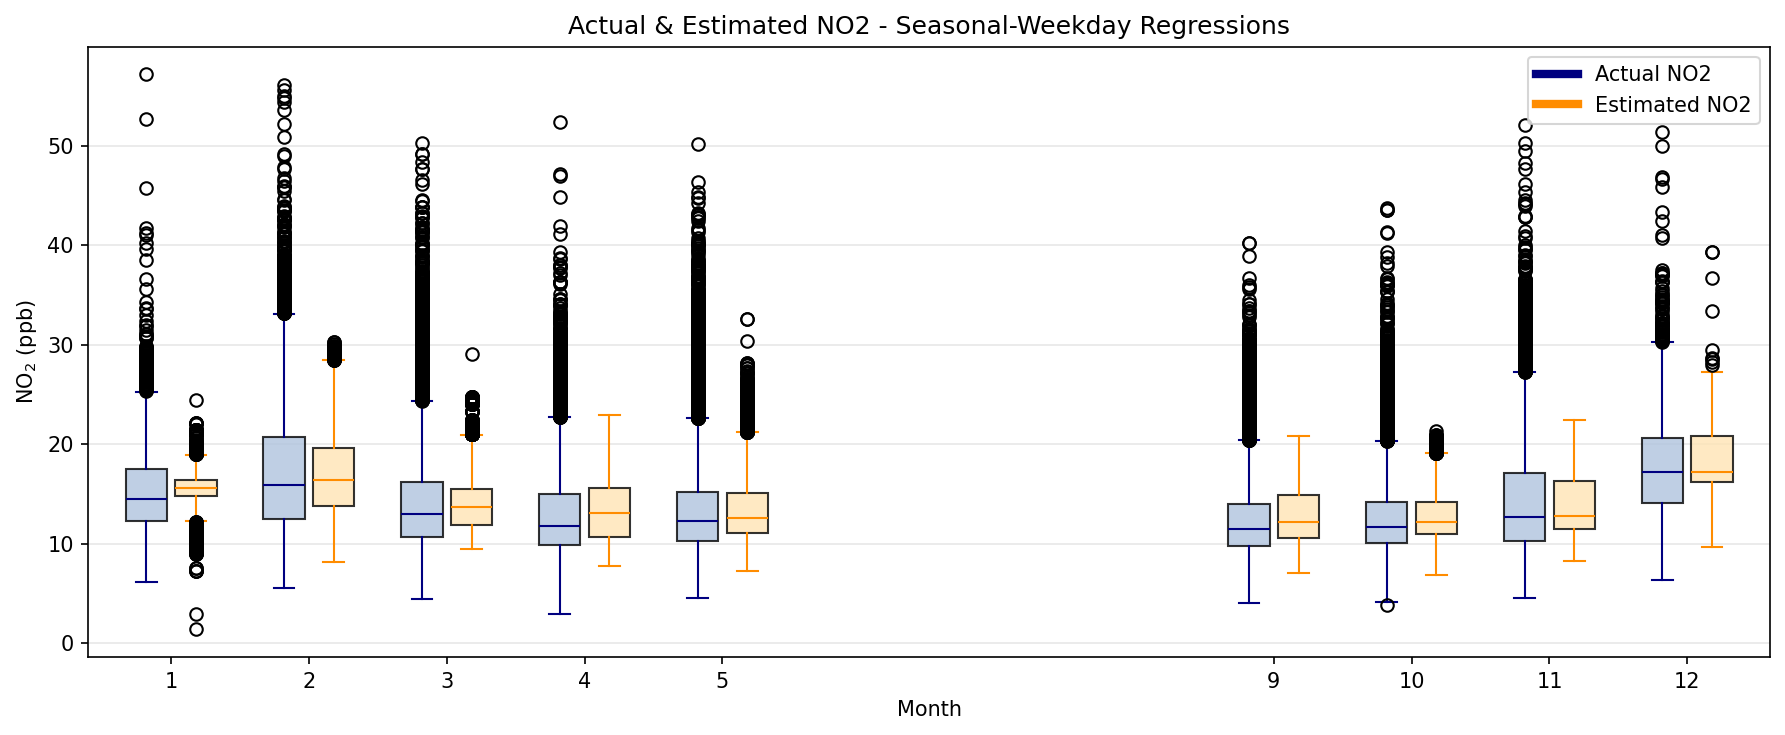

In [8]:

max_points_per_box = 20000

monthly_estimates_plot = (
    monthly_estimates_df[['month','weekday','sfc_no2_mean', 'no2_estimate','col_no2_mean']]
    .dropna(subset=['sfc_no2_mean', 'no2_estimate'])
    .copy()
)
monthly_estimates_plot['month'] = monthly_estimates_plot['month'].astype(int)
monthly_estimates_plot['weekday'] = monthly_estimates_plot['weekday'].astype(int)

month_labels = []
actual_by_month = []
estimated_by_month = []

rng = np.random.default_rng(41)

for month, group in monthly_estimates_plot.groupby('month', sort=True):
    month_labels.append(int(month))

    actual_values = group['sfc_no2_mean'].to_numpy(dtype=float)
    estimated_values = group['no2_estimate'].to_numpy(dtype=float)

    if len(actual_values) > max_points_per_box:
        sample_idx = rng.choice(len(actual_values), size=max_points_per_box, replace=False)
        actual_values = actual_values[sample_idx]
        estimated_values = estimated_values[sample_idx]

    actual_by_month.append(actual_values)
    estimated_by_month.append(estimated_values)

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [month - 0.18 for month in month_labels]
positions_estimated = [month + 0.18 for month in month_labels]

ax.boxplot(
    actual_by_month,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_month,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(month_labels)
ax.set_xticklabels(month_labels)
ax.set_xlim(min(month_labels) - 0.6, max(month_labels) + 0.6)
ax.set_xlabel('Month')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Actual & Estimated NO2 - Seasonal-Weekday Regressions')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()
plt.savefig('month-boxplot-seasonal-weekday.png')
plt.show()

#---------------------------------------------------------------------------------------------------------------------#


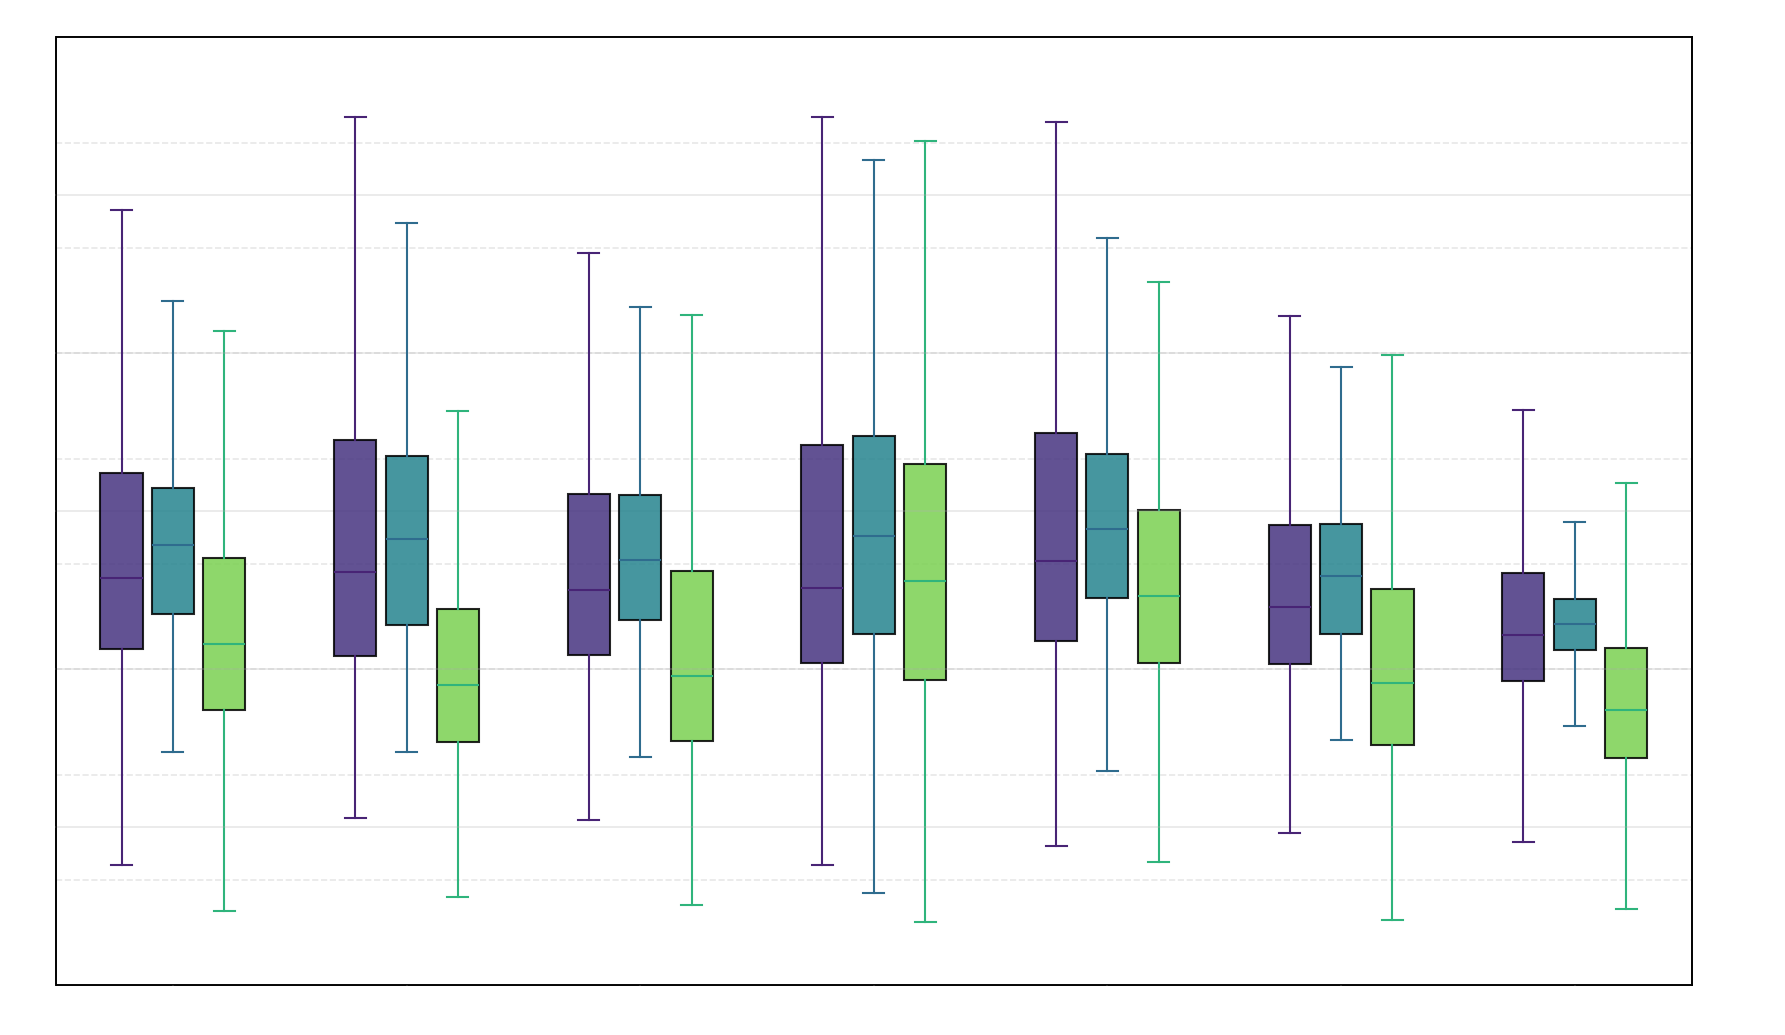

In [42]:
weekday_labels = []
weekday_names = []
actual_by_weekday = []
estimated_by_weekday = []
col_by_weekday = []
col_medians = []

for weekday, group in monthly_estimates_plot.groupby('weekday', sort=True):
    weekday_num = int(weekday)
    weekday_labels.append(weekday_num)
    weekday_names.append(weekday_map.get(weekday_num, weekday_num))

    actual_values = group['sfc_no2_mean'].to_numpy(dtype=float)
    estimated_values = group['no2_estimate'].to_numpy(dtype=float)
    col_values = group['col_no2_mean'].to_numpy(dtype=float)

    if len(actual_values) > max_points_per_box:
        sample_idx = rng.choice(len(actual_values), size=max_points_per_box, replace=False)
        actual_values = actual_values[sample_idx]
        estimated_values = estimated_values[sample_idx]
        col_values = col_values[sample_idx]

    actual_by_weekday.append(actual_values)
    estimated_by_weekday.append(estimated_values)
    col_by_weekday.append(col_values)
    col_medians.append(np.nanmedian(col_values))

fig, ax = plt.subplots(figsize=(12, 7))
ax2 = ax.twinx()

positions = np.arange(len(weekday_labels))
positions_actual = positions - 0.22
positions_estimated = positions
positions_col = positions + 0.22

viridis = plt.cm.viridis
colors = viridis([0.15, 0.45, 0.80])

ax.boxplot(
    actual_by_weekday,
    positions=positions_actual,
    widths=0.18,
    patch_artist=True,
    showfliers=False,
    boxprops=dict(facecolor=colors[0], alpha=0.85),
    medianprops=dict(color=viridis(0.10)),
    whiskerprops=dict(color=viridis(0.10)),
    capprops=dict(color=viridis(0.10)),
)
ax.boxplot(
    estimated_by_weekday,
    positions=positions_estimated,
    widths=0.18,
    patch_artist=True,
    showfliers=False,
    boxprops=dict(facecolor=colors[1], alpha=0.85),
    medianprops=dict(color=viridis(0.35)),
    whiskerprops=dict(color=viridis(0.35)),
    capprops=dict(color=viridis(0.35)),
)
ax2.boxplot(
    col_by_weekday,
    positions=positions_col,
    widths=0.18,
    patch_artist=True,
    showfliers=False,
    boxprops=dict(facecolor=colors[2], alpha=0.85),
    medianprops=dict(color=viridis(0.65)),
    whiskerprops=dict(color=viridis(0.65)),
    capprops=dict(color=viridis(0.65)),
)

# for pos, col_median in zip(positions, col_medians):
#     ax2.plot(
#         [pos - 0.16, pos + 0.16],
#         [col_median, col_median],
#         color=viridis(0.65),
#         linestyle='--',
#         linewidth=1.8,
#         alpha=0.95,
#     )
y2_min = -0.25e16
y2_max = 2e16
y2_step = 0.25e16
ax2_ticks = np.arange(y2_min, y2_max + y2_step, y2_step)

ax.set_zorder(ax2.get_zorder() + 1)
ax.patch.set_visible(False)

ax.set_xlim(min(positions) - 0.5, max(positions) + 0.5)
ax.set_xticks(positions)
ax.set_xticklabels(weekday_names)
ax.set_ylim(0, 30)
ax.set_xlabel('')
ax.set_ylabel('')
ax.set_title('')
ax.grid(True, axis='y', alpha=0.3)

ax2.set_axisbelow(True)
ax2.set_ylim(y2_min, y2_max)
ax2.set_yticks(ax2_ticks)
ax2.set_ylabel('')
ax2.grid(True, axis='y', alpha=0.3, linestyle='--')
# make ax background transparent so ax2 grid shows through
# actual_patch = plt.Line2D([0], [0], color=viridis(0.10), lw=4, label='Clarity NO$_2$')
# estimated_patch = plt.Line2D([0], [0], color=viridis(0.35), lw=4, label='Estimated NO$_2$')
# col_patch = plt.Line2D([0], [0], color=viridis(0.65), lw=4, label='TEMPO NO$_2$')
# ax.legend(handles=[actual_patch, estimated_patch, col_patch])

ax.yaxis.label.set_color('white')
ax.xaxis.label.set_color('white')
ax.tick_params(axis='y', colors='white')
ax.tick_params(axis='x', colors='white')

ax2.yaxis.label.set_color('white')
ax2.tick_params(axis='y', colors='white')

plt.tight_layout()
plt.savefig('boxplot-for-slides-clean.png',dpi=300)

plt.show()

# Monthly Day of Week Regression

In [38]:

var_select = ['sfc_no2_mean','col_no2_mean','pbl_mean', 'solar_zenith_mean', 'u10m_mean','v10m_mean']
target_col = 'sfc_no2_mean'
feature_cols = ['col_no2_mean', 'pbl_mean', 'solar_zenith_mean','u10m_mean','v10m_mean']
meta_cols = ['datetime', 'latitude', 'longitude']

def estimate_no2_from_model(x):
    return (
        intercept
        + coef[0] * x['col_no2_mean']
        + coef[1] * x['pbl_mean']
        + coef[2] * x['solar_zenith_mean']
        + coef[3] * x['u10m_mean']
        + coef[4] * x['v10m_mean']
    )

hourly = hourly.mask(hourly['season']=='Summer')
hourly = hourly.copy()
hourly['month_period'] = hourly['datetime'].dt.to_period('M')

month_results = []
monthly_estimates = []

for month_period in sorted(hourly['month_period'].dropna().unique()):
    for weekday in sorted(hourly['weekday'].dropna().unique()):
        month_frame = hourly.loc[
            ((hourly['weekday'] == weekday) & (hourly['month_period'] == month_period)),
            meta_cols + var_select
        ].dropna().copy()
        if len(month_frame) < 10:
            continue

        train_df, test_df = train_test_split(month_frame, test_size=0.3, random_state=42)

        scaler_x = StandardScaler().fit(train_df[feature_cols])
        scaler_y = StandardScaler().fit(train_df[[target_col]])

        x_train = pd.DataFrame(scaler_x.transform(train_df[feature_cols]), columns=feature_cols, index=train_df.index)
        x_test = pd.DataFrame(scaler_x.transform(test_df[feature_cols]), columns=feature_cols, index=test_df.index)

        y_train = pd.Series(scaler_y.transform(train_df[[target_col]]).ravel(), name=target_col, index=train_df.index)
        y_test = pd.Series(scaler_y.transform(test_df[[target_col]]).ravel(), name=target_col, index=test_df.index)

        model = linear_model.LinearRegression().fit(X=x_train, y=y_train)

        intercept = float(model.intercept_)
        coef = np.ravel(model.coef_)

        train_est_scaled = x_train.apply(estimate_no2_from_model, axis=1)
        test_est_scaled = x_test.apply(estimate_no2_from_model, axis=1)

        train_estimates = scaler_y.inverse_transform(pd.DataFrame(train_est_scaled, columns=['no2_estimate'])).ravel()
        test_estimates = scaler_y.inverse_transform(pd.DataFrame(test_est_scaled, columns=['no2_estimate'])).ravel()

        train_est = train_df[meta_cols + ['sfc_no2_mean']].copy()
        train_est['no2_estimate'] = train_estimates
        train_est['weekday'] = weekday 
        train_est['month'] = month_period.month
        train_est['month_period'] = month_period
        train_est['split'] = 'train'
        train_est['residual'] = train_est['sfc_no2_mean'] - train_est['no2_estimate']

        test_est = test_df[meta_cols + ['sfc_no2_mean']].copy()
        test_est['no2_estimate'] = test_estimates
        test_est['weekday'] = weekday 
        test_est['month'] = month_period.month
        test_est['month_period'] = month_period
        test_est['split'] = 'test'
        test_est['residual'] = test_est['sfc_no2_mean'] - test_est['no2_estimate']

        monthly_estimates.append(pd.concat([train_est, test_est], axis=0))

        month_results.append({
            'weekday': weekday,
            'month': month_period.month,
            'year': month_period.year,
            'month_period': month_period,
            'month_label': month_period.strftime('%b %Y'),
            'train_rows': len(train_df),
            'test_rows': len(test_df),
            'train_r2': r2_score(y_train, model.predict(x_train)),
            'test_r2': r2_score(y_test, model.predict(x_test)),
            'train_rmse': root_mean_squared_error(y_train, model.predict(x_train)),
            'test_rmse': root_mean_squared_error(y_test, model.predict(x_test)),
            'intercept': intercept,
            'coef_col_no2': float(coef[0]),
            'coef_pbl': float(coef[1]),
            'coef_sza': float(coef[2]),
            'coef_u10m': float(coef[3]),
            'coef_v10m': float(coef[4]),
        })

model_vals = pd.DataFrame(month_results)
print(model_vals)

monthly_estimates_df = pd.concat(monthly_estimates, axis=0, ignore_index=True)
print(monthly_estimates_df.head())

monthly_estimates_df = monthly_estimates_df.sort_values(by='datetime')

monthly_estimates_df.to_csv(datapath + "month-dayofweek-no2-estimates.csv")

monthly_estimates_df

KeyboardInterrupt: 

## Plots

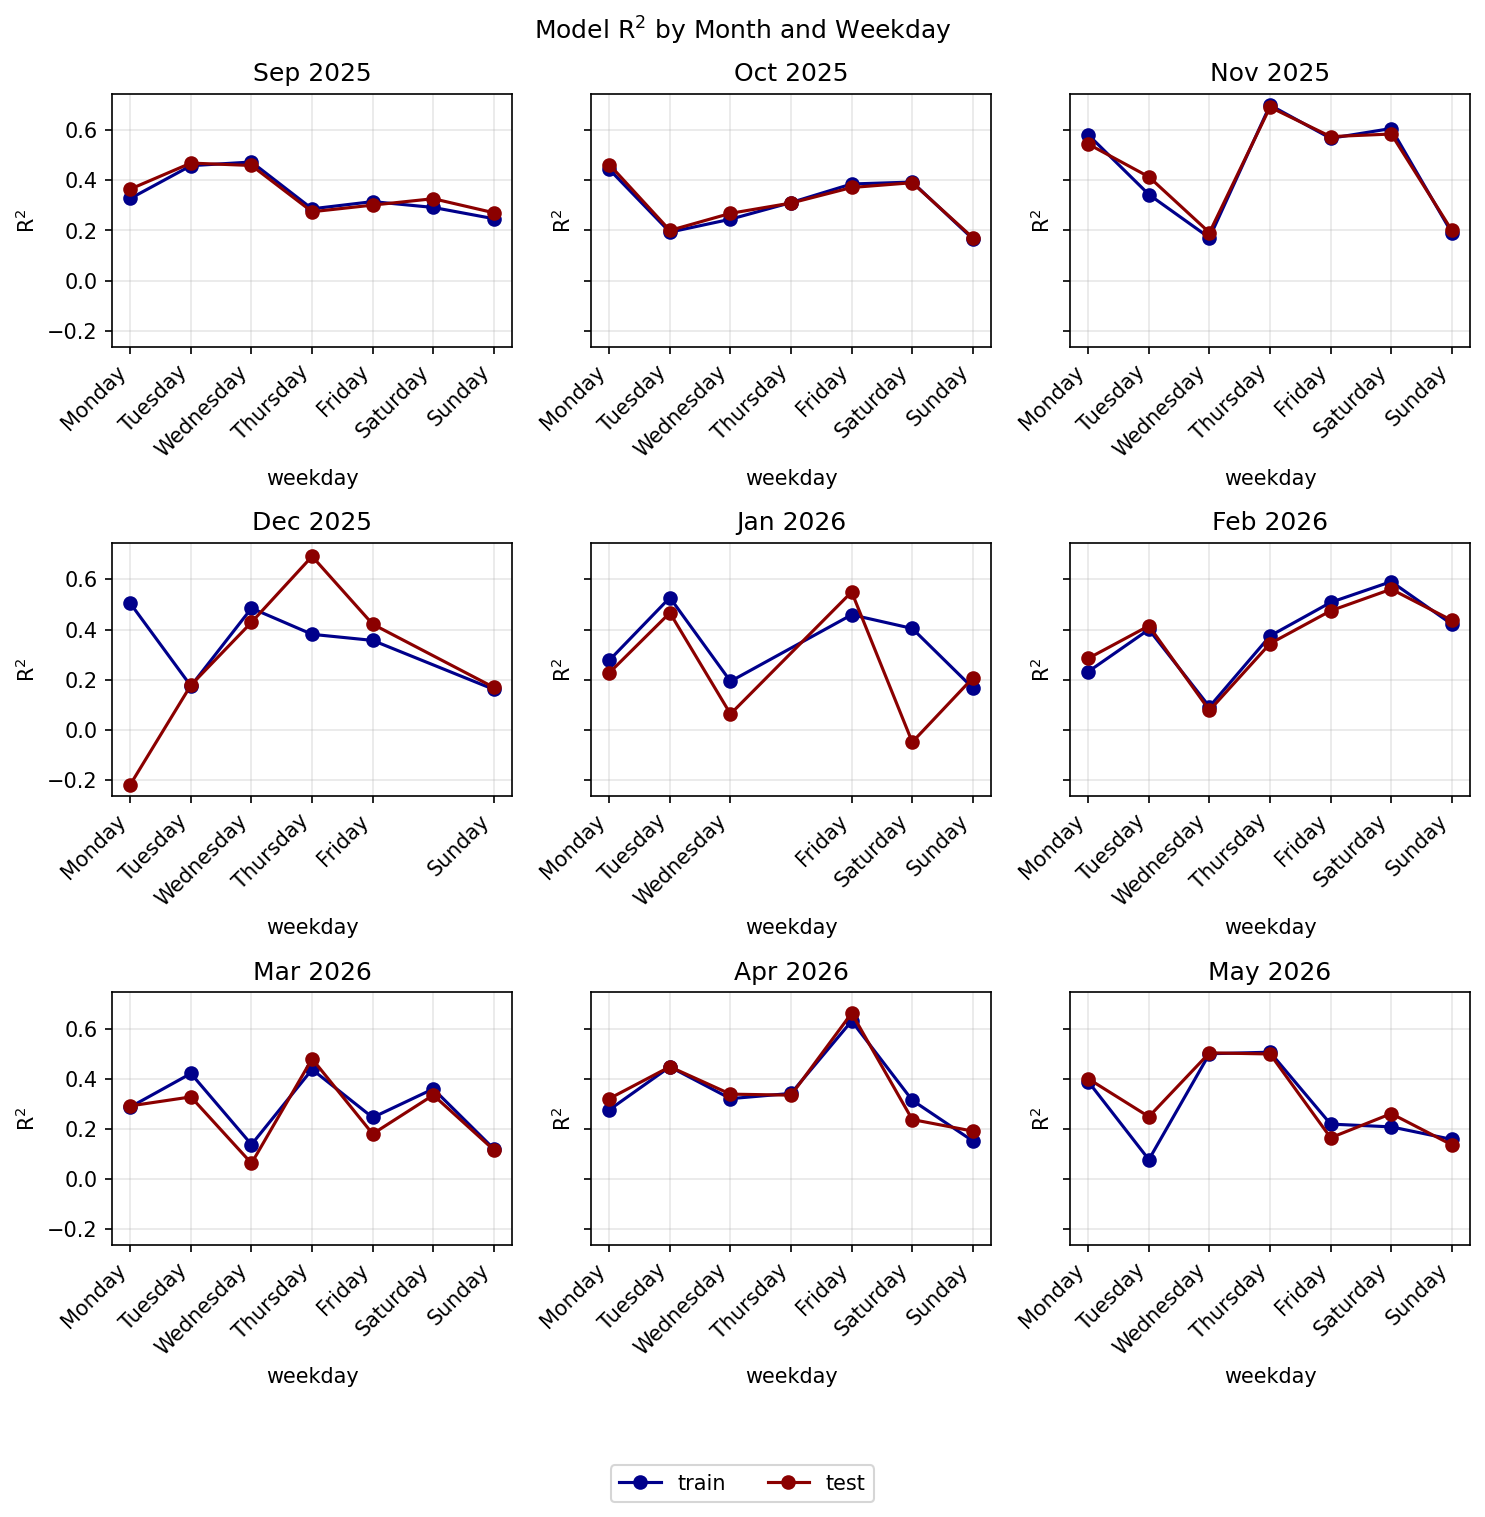

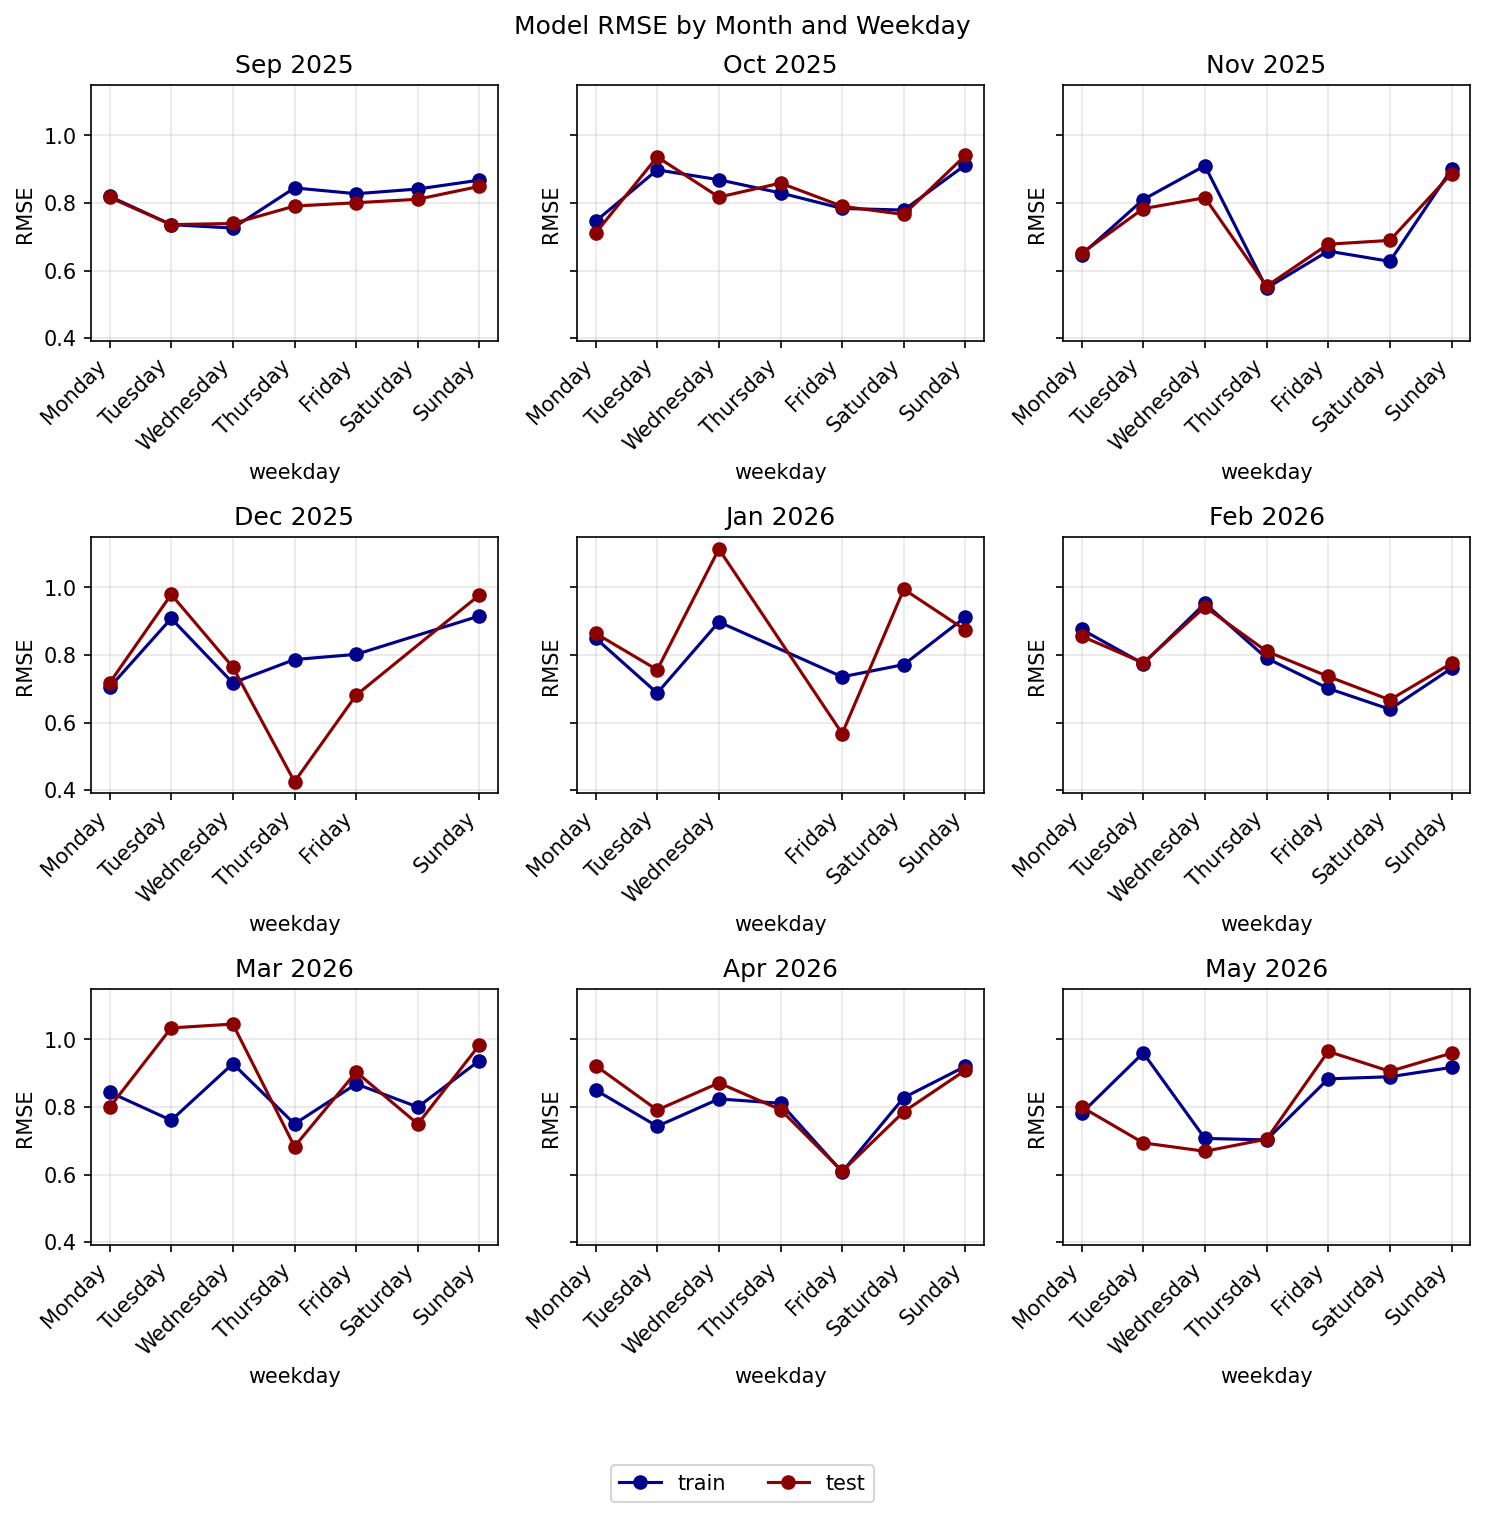

In [ ]:
month_order = sorted(model_vals['month_period'].dropna().unique())

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(10, 10),
    sharey=True,
)
axes = np.ravel(axes)

for ax, month_period in zip(axes, month_order):
    month_data = model_vals[model_vals['month_period'] == month_period]
    ax.plot(month_data['weekday'], month_data['train_r2'], marker='o', color='darkblue', label='train')
    ax.plot(month_data['weekday'], month_data['test_r2'], marker='o', color='darkred', label='test')
    ax.set_xticks(month_data['weekday'])
    ax.set_xticklabels(month_data['weekday'].map(weekday_map), rotation=45, ha='right')
    ax.set_xlabel('weekday')
    ax.set_ylabel('R$^2$')
    ax.set_title(f'{month_period.strftime("%b %Y")}')
    ax.grid(True, alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=2)
fig.suptitle('Model R$^2$ by Month and Weekday')
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig('r2-month-weekday.png')
plt.show()

fig, axes = plt.subplots(
    nrows=3,
    ncols=3,
    figsize=(10, 10),
    sharey=True,
)
axes = np.ravel(axes)

for ax, month_period in zip(axes, month_order):
    month_data = model_vals[model_vals['month_period'] == month_period]
    ax.plot(month_data['weekday'], month_data['train_rmse'], marker='o', color='darkblue', label='train')
    ax.plot(month_data['weekday'], month_data['test_rmse'], marker='o', color='darkred', label='test')
    ax.set_xticks(month_data['weekday'])
    ax.set_xticklabels(month_data['weekday'].map(weekday_map), rotation=45, ha='right')
    ax.set_xlabel('weekday')
    ax.set_ylabel('RMSE')
    ax.set_title(f'{month_period.strftime("%b %Y")}')
    ax.grid(True, alpha=0.3)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, 0.02), ncol=2)
fig.suptitle('Model RMSE by Month and Weekday')
plt.tight_layout(rect=(0, 0.05, 1, 1))
plt.savefig('rmse-month-weekday.png')
plt.show()

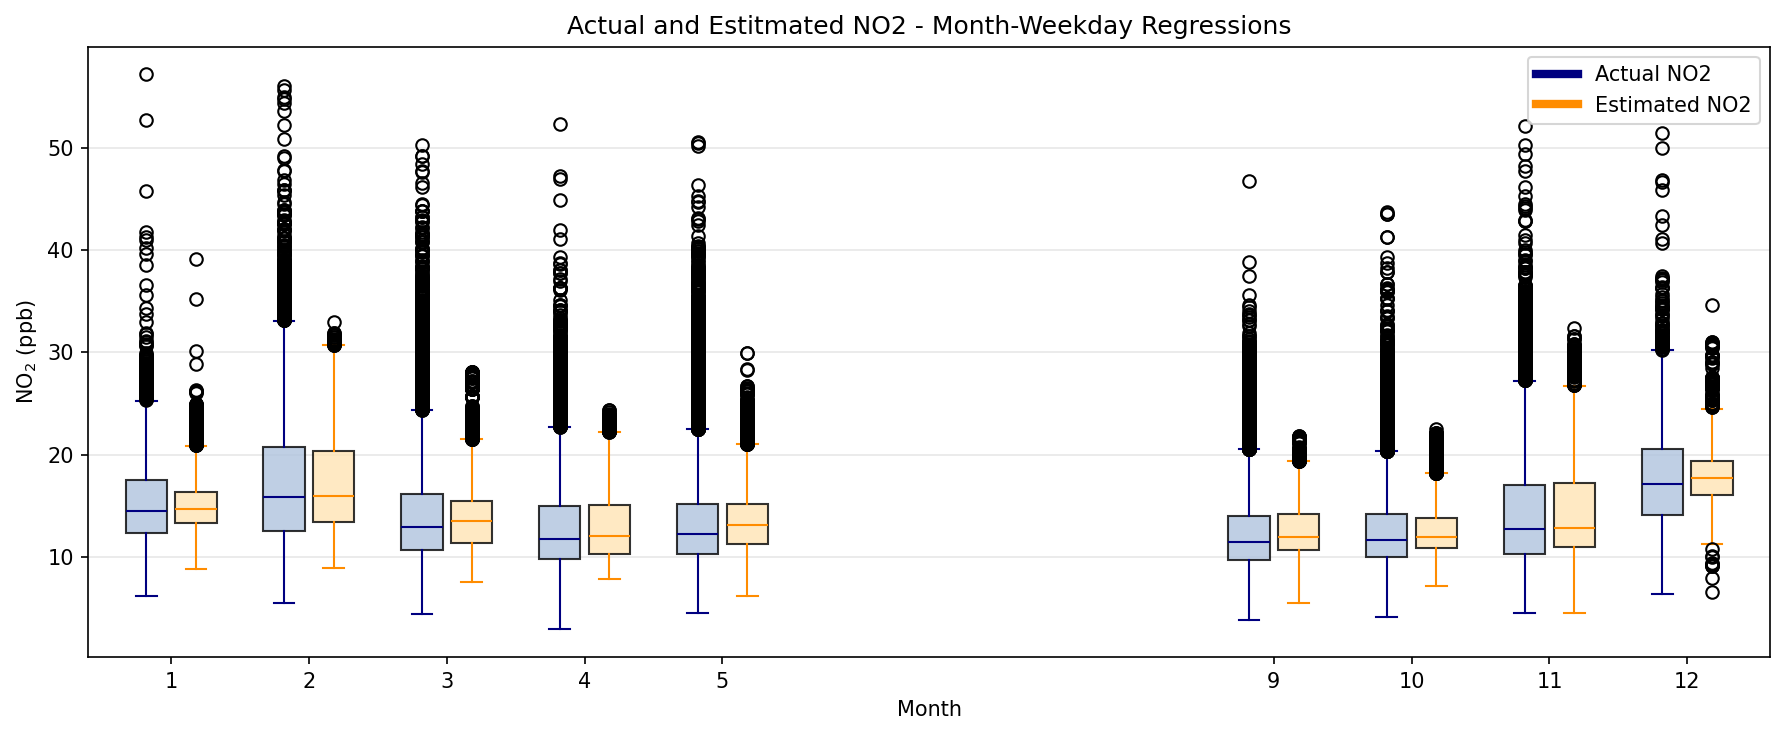

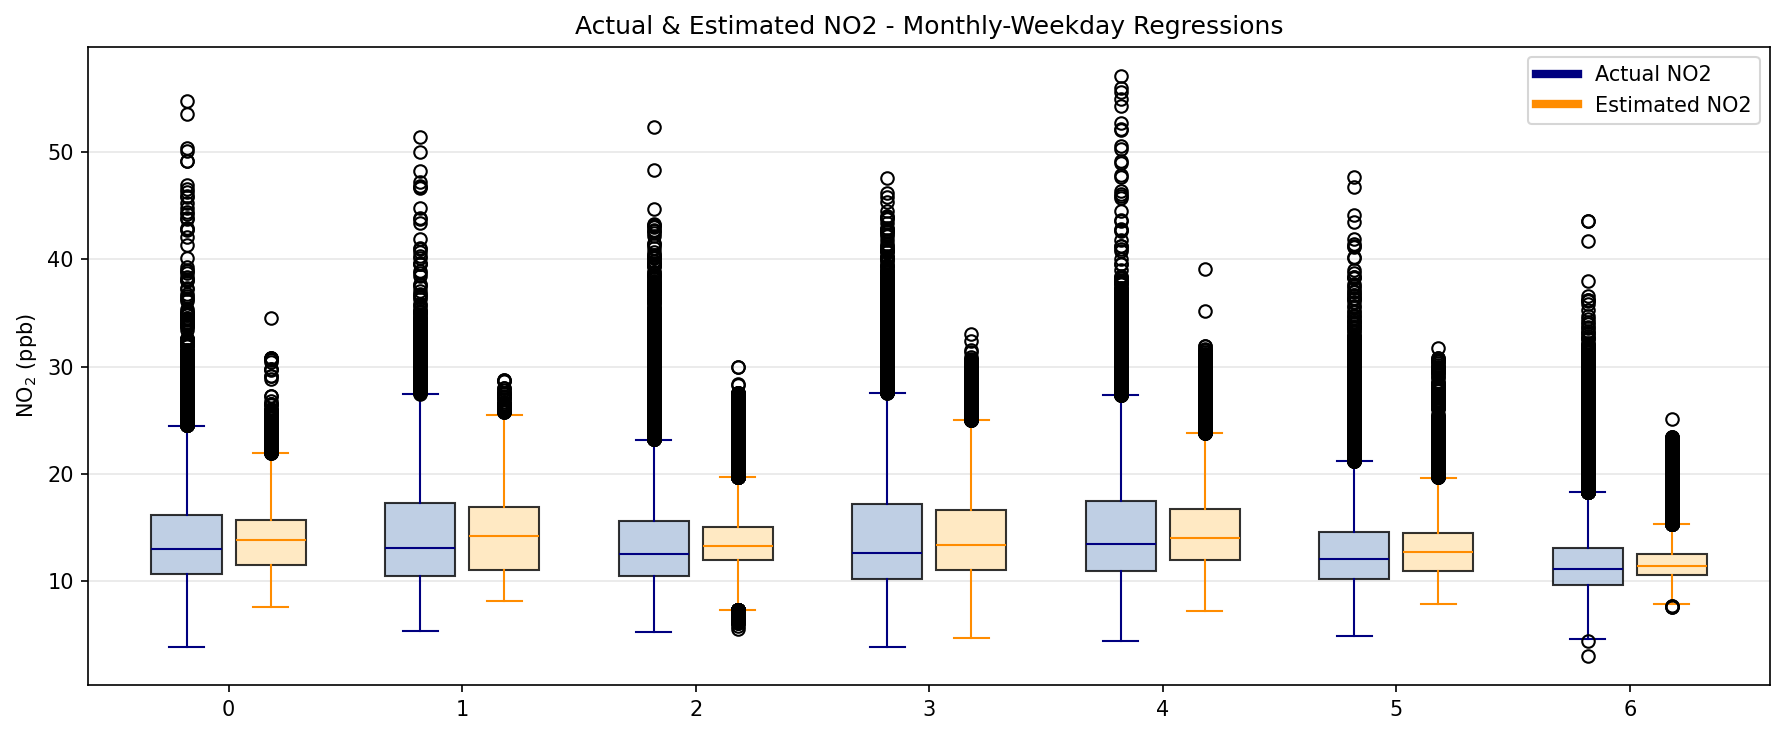

In [ ]:

max_points_per_box = 20000

monthly_estimates_plot = (
    monthly_estimates_df[['datetime','month', 'sfc_no2_mean', 'no2_estimate']]
    .dropna(subset=['sfc_no2_mean', 'no2_estimate'])
    .copy()
)
monthly_estimates_plot['month'] = monthly_estimates_plot['month'].astype(int)
monthly_estimates_plot['weekday'] = monthly_estimates_plot['datetime'].dt.weekday

months = []
actual_by_hour = []
estimated_by_hour = []

rng = np.random.default_rng(41)

for month, group in monthly_estimates_plot.groupby('month', sort=True):
    months.append(int(month))

    actual_values = group['sfc_no2_mean'].to_numpy(dtype=float)
    estimated_values = group['no2_estimate'].to_numpy(dtype=float)

    if len(actual_values) > max_points_per_box:
        sample_idx = rng.choice(len(actual_values), size=max_points_per_box, replace=False)
        actual_values = actual_values[sample_idx]
        estimated_values = estimated_values[sample_idx]

    actual_by_hour.append(actual_values)
    estimated_by_hour.append(estimated_values)

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [month - 0.18 for month in months]
positions_estimated = [month + 0.18 for month in months]

ax.boxplot(
    actual_by_hour,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_hour,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(months)
ax.set_xticklabels(months)
ax.set_xlim(min(months) - 0.6, max(months) + 0.6)
ax.set_xlabel('Month')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Actual and Estitmated NO2 - Month-Weekday Regressions')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()
plt.savefig('month-boxplot-month-weekday.png')
plt.show()

#---------------------------------------------------------------------------------------------------------------------#

weekday_labels = []
actual_by_weekday = []
estimated_by_weekday = []

for weekday, group in monthly_estimates_plot.groupby('weekday', sort=True):
    weekday_labels.append(int(weekday))

    actual_values = group['sfc_no2_mean'].to_numpy(dtype=float)
    estimated_values = group['no2_estimate'].to_numpy(dtype=float)

    if len(actual_values) > max_points_per_box:
        sample_idx = rng.choice(len(actual_values), size=max_points_per_box, replace=False)
        actual_values = actual_values[sample_idx]
        estimated_values = estimated_values[sample_idx]

    actual_by_weekday.append(actual_values)
    estimated_by_weekday.append(estimated_values)

fig, ax = plt.subplots(figsize=(12, 5))

positions_actual = [weekday - 0.18 for weekday in weekday_labels]
positions_estimated = [weekday + 0.18 for weekday in weekday_labels]

ax.boxplot(
    actual_by_weekday,
    positions=positions_actual,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='lightsteelblue', alpha=0.8),
    medianprops=dict(color='navy'),
    whiskerprops=dict(color='navy'),
    capprops=dict(color='navy'),
)
ax.boxplot(
    estimated_by_weekday,
    positions=positions_estimated,
    widths=0.3,
    patch_artist=True,
    boxprops=dict(facecolor='moccasin', alpha=0.8),
    medianprops=dict(color='darkorange'),
    whiskerprops=dict(color='darkorange'),
    capprops=dict(color='darkorange'),
)

ax.set_xticks(weekday_labels)
ax.set_xticklabels(weekday_labels)
ax.set_xlim(min(weekday_labels) - 0.6, max(weekday_labels) + 0.6)
ax.set_xlabel('')
ax.set_ylabel('NO$_2$ (ppb)')
ax.set_title('Actual & Estimated NO2 - Monthly-Weekday Regressions')
ax.grid(True, axis='y', alpha=0.3)

actual_patch = plt.Line2D([0], [0], color='navy', lw=4, label='Actual NO2')
estimated_patch = plt.Line2D([0], [0], color='darkorange', lw=4, label='Estimated NO2')
ax.legend(handles=[actual_patch, estimated_patch])

plt.tight_layout()
plt.savefig('weekday-boxplot-monthly-weekday.png')
plt.show()

# Spatial Plots of Fused Data

## Seasonal - Weekday

In [9]:
seasonal_weekday = pd.read_csv(datapath+"seasonal-dayofweek-no2-estimates.csv")
seasonal_weekday['datetime'] = pd.to_datetime(seasonal_weekday['datetime'], errors='coerce')
seasonal_weekday['hour'] = seasonal_weekday['datetime'].dt.hour
seasonal_weekday['weekday'] = seasonal_weekday['datetime'].dt.weekday
seasonal_weekday['season'] = seasonal_weekday['month'].map(season_map)
subset = seasonal_weekday[['datetime','latitude','longitude','residual']].set_index(['datetime','latitude','longitude'])

seasonal_weekday2 = seasonal_weekday[['season','datetime','latitude','longitude','residual','no2_estimate']]

sw_rast = subset.to_xarray()

seasonal_weekday2

,season,datetime,latitude,longitude,residual,no2_estimate
0,Fall,2025-09-04 12:00:00,41.83,-87.65,0.906105,15.472772
1,Fall,2025-09-04 12:00:00,41.69,-87.53,2.463508,15.543508
2,Fall,2025-09-04 12:00:00,41.83,-87.67,2.138787,15.495453
3,Fall,2025-09-04 12:00:00,41.67,-87.67,2.956058,15.553558
4,Fall,2025-09-04 12:00:00,41.79,-87.77,6.422788,15.747788
...,...,...,...,...,...,...
143034,Spring,2026-05-31 23:00:00,41.97,-87.85,1.017978,12.123887
143035,Spring,2026-05-31 23:00:00,41.95,-87.85,0.248305,11.875305
143036,Spring,2026-05-31 23:00:00,41.97,-87.83,0.190936,12.121845
143037,Spring,2026-05-31 23:00:00,42.01,-87.77,1.893047,12.534047


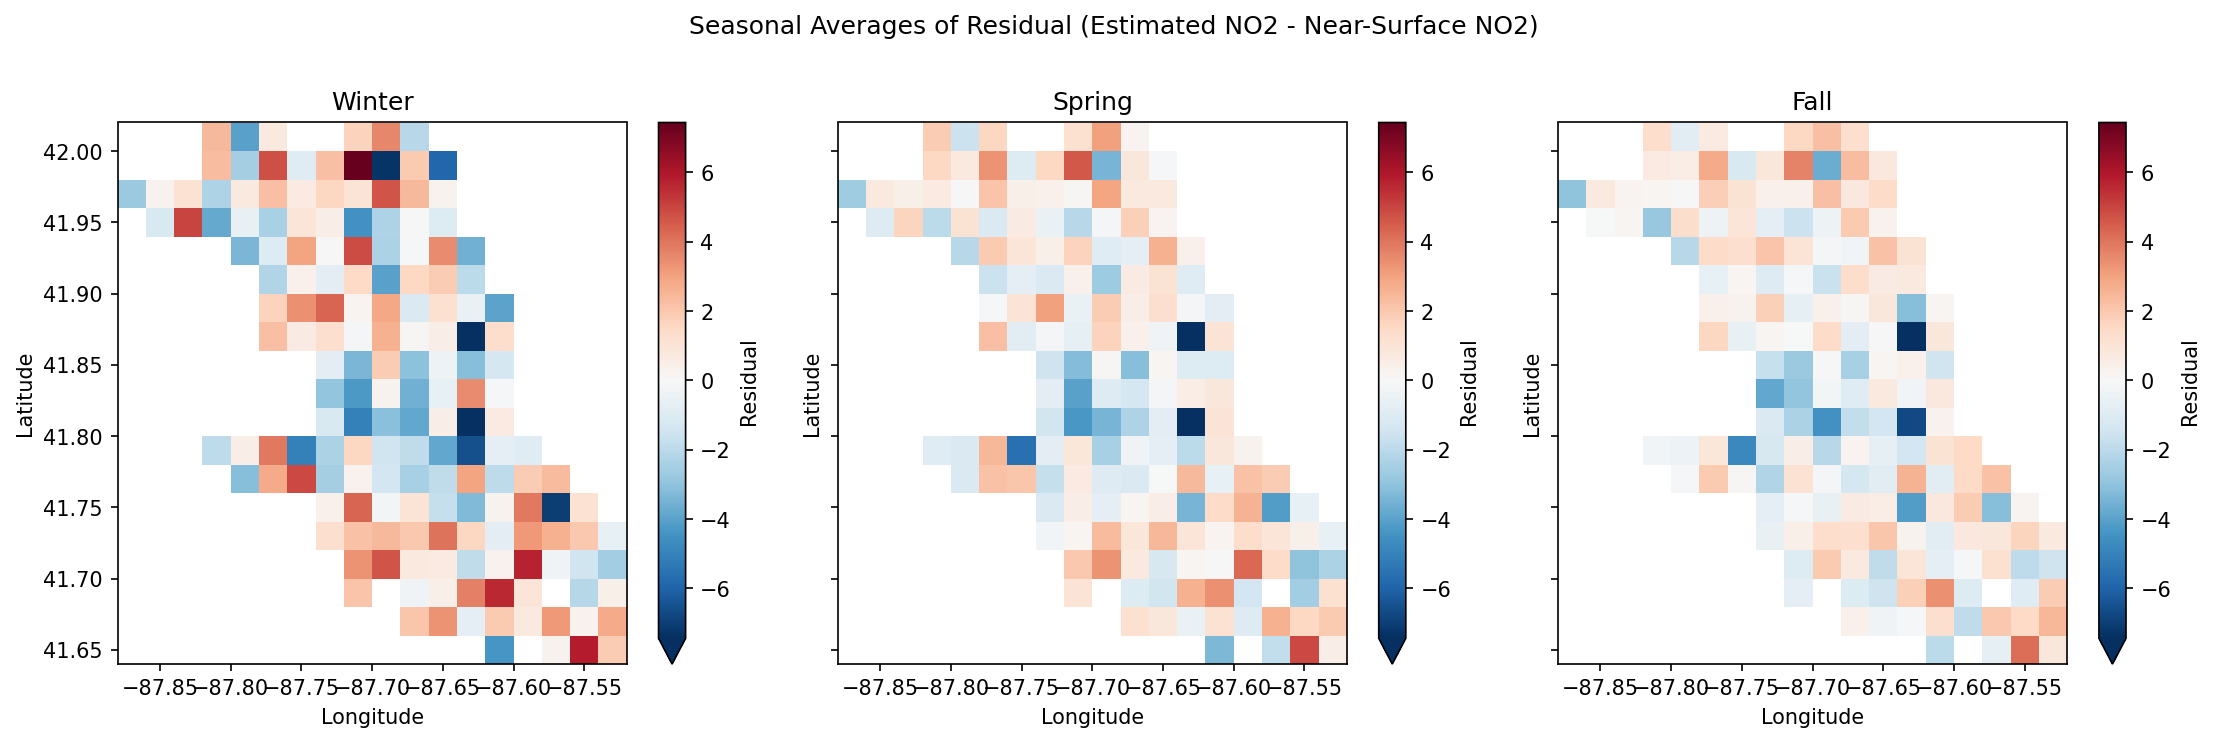

In [6]:
import matplotlib.pyplot as plt

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
seasonal_maps = []

for season in season_order:
    if season not in seasonal_weekday['season'].dropna().unique():
        continue

    season_subset = seasonal_weekday.loc[seasonal_weekday['season'] == season, ['datetime', 'latitude', 'longitude', 'residual']]
    season_subset = season_subset.set_index(['datetime', 'latitude', 'longitude'])
    season_rast = season_subset.to_xarray()
    seasonal_maps.append((season, season_rast['residual'].mean(dim='datetime', skipna=True)))

all_residuals = [mean_map.values.ravel() for _, mean_map in seasonal_maps]
max_abs = max(abs(np.nanmax(values)) for values in all_residuals if values.size > 0)
shared_vmax = max_abs
shared_vmin = -max_abs

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (season, mean_map) in zip(axes, seasonal_maps):
    mean_map.plot(
        x='longitude',
        y='latitude',
        cmap='RdBu_r',
        ax=ax,
        add_colorbar=True,
        vmin=shared_vmin,
        vmax=shared_vmax,
        cbar_kwargs={'label': 'Residual'}
    )
    ax.set_title(season)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

for ax in axes[len(seasonal_maps):]:
    ax.set_visible(False)

fig.suptitle('Seasonal Averages of Residual (Estimated NO2 - Near-Surface NO2) ')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('seasonal-weekday-spatial-residuals.png')
plt.show()


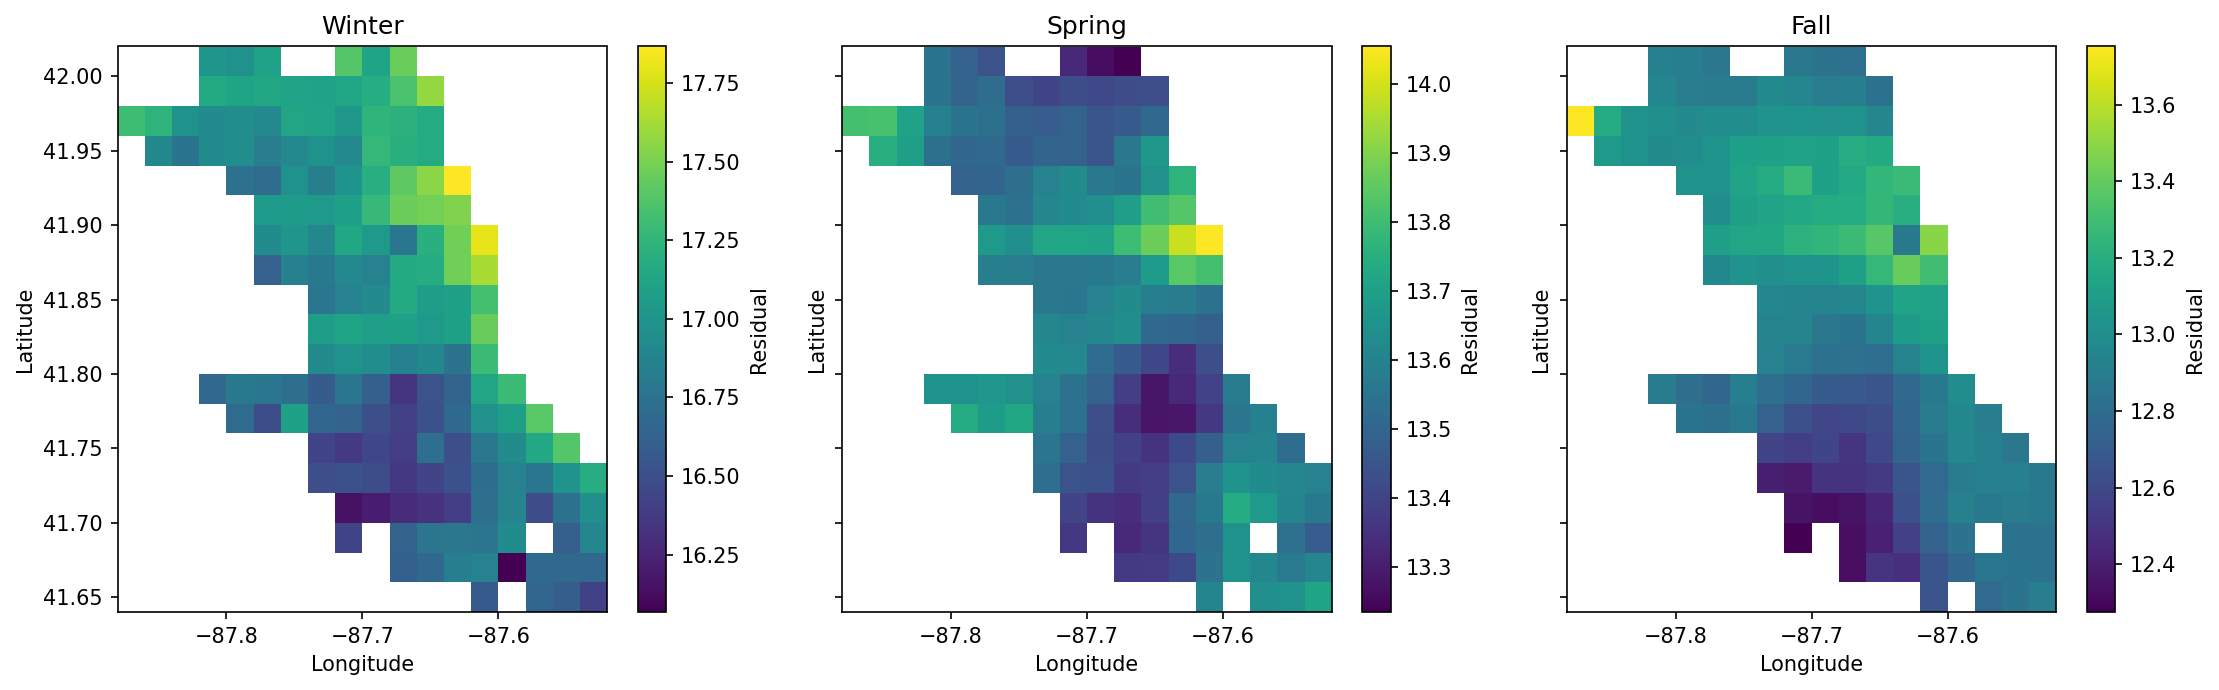

In [ ]:

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
seasonal_maps = []

for season in season_order:
    if season not in seasonal_weekday['season'].dropna().unique():
        continue

    season_subset = seasonal_weekday.loc[seasonal_weekday['season'] == season, ['datetime', 'latitude', 'longitude', 'no2_estimate']]
    season_subset = season_subset.set_index(['datetime', 'latitude', 'longitude'])
    season_rast = season_subset.to_xarray()
    seasonal_maps.append((season, season_rast['no2_estimate'].mean(dim='datetime', skipna=True)))

all_residuals = [mean_map.values.ravel() for _, mean_map in seasonal_maps]
max_abs = max(abs(np.nanmax(values)) for values in all_residuals if values.size > 0)
min_abs = min(abs(np.nanmax(values)) for values in all_residuals if values.size > 0)

# shared_vmax = 20
# shared_vmin = 14   

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(15, 5), sharex=True, sharey=True)
axes = axes.flatten()

for ax, (season, mean_map) in zip(axes, seasonal_maps):
    mean_map.plot(
        x='longitude',
        y='latitude',
        cmap='viridis',
        ax=ax,
        add_colorbar=True,
        # vmin=shared_vmin,
        # vmax=shared_vmax,
        cbar_kwargs={'label': 'Residual'}
    )
    ax.set_title(season)
    ax.set_xlabel('Longitude')
    ax.set_ylabel('Latitude')

for ax in axes[len(seasonal_maps):]:
    ax.set_visible(False)

fig.suptitle('')
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig('seasonal-fused-data-spatial-.png')
plt.show()

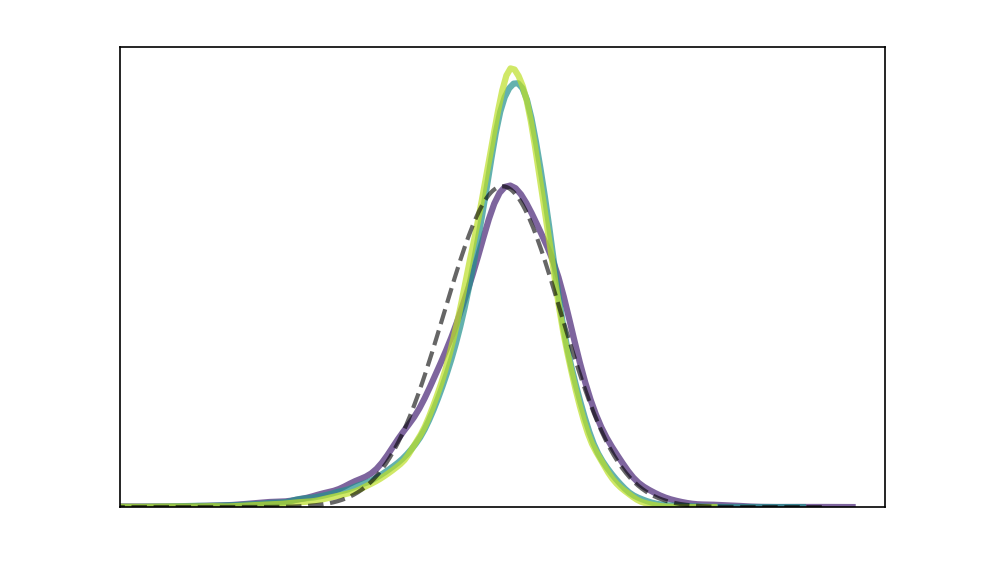

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import kurtosis, norm

white_annotations = True 
filename = 'seasonal-weekday-kde-residuals-clean.png'
annotation_color = 'white' if white_annotations else 'black'
show_legend = not white_annotations

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
seasonal_residuals = []

for season in season_order:
    if season not in seasonal_weekday['season'].dropna().unique():
        continue

    season_values = seasonal_weekday.loc[seasonal_weekday['season'] == season, 'residual'].dropna()
    if not season_values.empty:
        seasonal_residuals.append((season, season_values))

fig, ax = plt.subplots(figsize=(6, 4))
viridis_colors = plt.cm.viridis(np.linspace(0.10, 0.90, len(seasonal_residuals)))

for i, (season, values) in enumerate(seasonal_residuals):
    sns.kdeplot(
        values,
        ax=ax,
        label=season,
        fill=False,
        alpha=0.7,
        linewidth=3,
        color=viridis_colors[i]
    )

    kurt = kurtosis(values, fisher=False, bias=False)
    ax.text(
        0.98,
        0.92 - 0.06 * i,
        f'{season}: kurtosis = {kurt:.2f}',
        transform=ax.transAxes,
        ha='right',
        va='top',
        fontsize=9,
        color=annotation_color,
    )

# Reference normal distribution with mu=0 and sigma from all residuals.
all_residuals = seasonal_weekday['residual'].dropna().to_numpy(dtype=float)
sigma = np.std(all_residuals, ddof=1)

if all_residuals.size > 1 and sigma > 0:
    x_min = min(np.min(all_residuals), -4 * sigma)
    x_max = max(np.max(all_residuals), 4 * sigma)
    x_grid = np.linspace(x_min, x_max, 500)
    normal_pdf = norm.pdf(x_grid, loc=0.0, scale=sigma)
    ax.plot(
        x_grid,
        normal_pdf,
        linestyle='--',
        linewidth=2,
        color='black',
        alpha=0.6,
        label=f'Normal(μ=0, σ={sigma:.2f})'
    )

ax.set_title('Kernel Density Estimate of Model Residuals by Season (Est NO2 - Actual NO2)', color=annotation_color)
ax.set_xlabel('Residual', color=annotation_color)
ax.set_ylabel('Density', color=annotation_color)
ax.set_xlim(-25, 25)
ax.tick_params(axis='x', colors=annotation_color)
ax.tick_params(axis='y', colors=annotation_color)

if show_legend:
    ax.legend()

plt.tight_layout()
plt.savefig(filename, dpi=300)
plt.show()

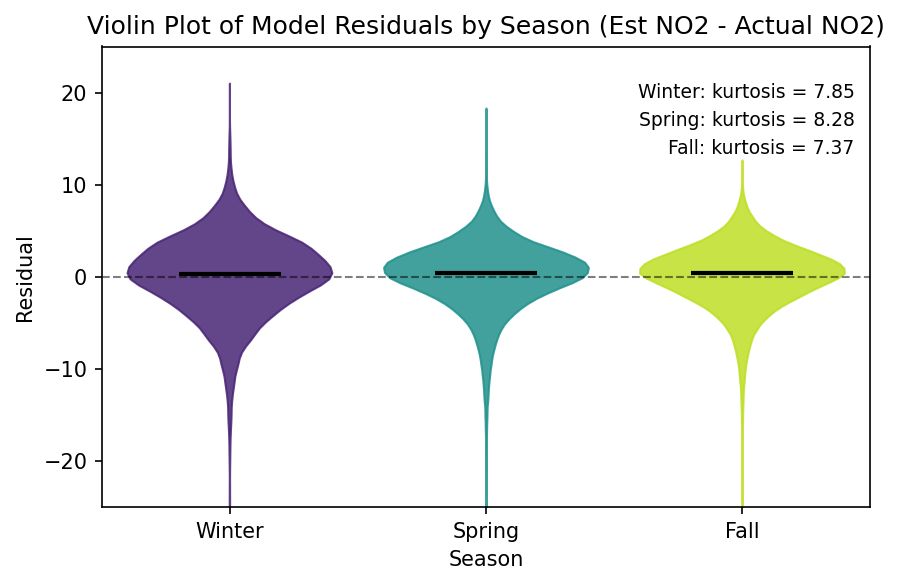

In [31]:
white_annotations = False
filename = 'seasonal-weekday-violin-residuals-clean.png'
annotation_color = 'white' if white_annotations else 'black'

season_order = ['Winter', 'Spring', 'Summer', 'Fall']
violin_data = []

for season in season_order:
    if season not in seasonal_weekday['season'].dropna().unique():
        continue

    season_values = seasonal_weekday.loc[seasonal_weekday['season'] == season, 'residual'].dropna()
    if not season_values.empty:
        violin_data.append((season, season_values))

fig, ax = plt.subplots(figsize=(6, 4))
viridis_colors = plt.cm.viridis(np.linspace(0.10, 0.90, len(violin_data)))

if violin_data:
    data_values = [values.to_numpy(dtype=float) for _, values in violin_data]
    positions = np.arange(1, len(violin_data) + 1)

    parts = ax.violinplot(
        data_values,
        positions=positions,
        showmeans=False,
        showmedians=True,
        showextrema=False,
        widths=0.8,
    )

    for body, color in zip(parts['bodies'], viridis_colors):
        body.set_facecolor(color)
        body.set_edgecolor(color)
        body.set_alpha(0.85)

    if 'cmedians' in parts:
        parts['cmedians'].set_color('black')
        parts['cmedians'].set_linewidth(2)

    ax.set_xticks(positions)
    ax.set_xticklabels([season for season, _ in violin_data], color=annotation_color)

    for i, (season, values) in enumerate(violin_data):
        kurt = kurtosis(values, fisher=False, bias=False)
        ax.text(
            0.98,
            0.92 - 0.06 * i,
            f'{season}: kurtosis = {kurt:.2f}',
            transform=ax.transAxes,
            ha='right',
            va='top',
            fontsize=9,
            color=annotation_color,
        )

    ax.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)

ax.set_title('Violin Plot of Model Residuals by Season (Est NO2 - Actual NO2)', color=annotation_color)
ax.set_xlabel('Season', color=annotation_color)
ax.set_ylabel('Residual', color=annotation_color)
ax.tick_params(axis='x', colors=annotation_color)
ax.tick_params(axis='y', colors=annotation_color)
ax.set_xlim(0.5, len(violin_data) + 0.5)
ax.set_ylim(-25, 25)

plt.tight_layout()
plt.savefig(filename, dpi=300)
plt.show()

## Monthly - Weekday

# TESTING BELOW HERE

In [45]:



months = chi_result_monthly['month_year'].unique()
months = months[months.argsort()]

start_date = chi_result_monthly['month_year'].min()
end_date = chi_result_monthly['month_year'].max()

delta = relativedelta(months=1)

fig, axes = plt.subplots(
    nrows=3, ncols=4,
    figsize=(20, 15)
)

for ax, month in zip(axes.flatten(), range(1,13)):
# while start_date <= end_date:
    # ax = axes[i]

    # Base Chicago boundary
    chicago.plot(color='white', edgecolor='black', ax=ax)
    
    # Filter to month
    monthly_data = chi_result_monthly[chi_result_monthly['month_year'] == start_date]
    
    if not monthly_data.empty:
        monthly_data.plot(ax=ax, column='avg_value', cmap='BuPu',
                          vmin=chi_result_monthly['avg_value'].min(),
                          vmax=chi_result_monthly['avg_value'].max())
    
    # ax.set_title(calendar.month_name[month])
    # ax.axis('off')
    title_date = dt.date(start_date.year, start_date.month, start_date.day).strftime('%B %Y')
    ax.set_title(title_date, fontsize=12)
    ax.axis('off')

    start_date += delta

# Shared colorbar
sm = plt.cm.ScalarMappable(
    cmap='BuPu',
    norm=plt.Normalize(
        vmin=chi_result_monthly['avg_value'].min(),
        vmax=chi_result_monthly['avg_value'].max()
    )
)
sm._A = []
fig.colorbar(sm, ax=axes, shrink=0.5, label='Average NO2')

plt.suptitle('Monthly Avg NO2 - Chicago', fontsize=16, y=1.02)
plt.tight_layout()
plt.savefig("month_avg_community.png")
plt.show()

NameError: name 'chi_result_monthly' is not defined